# **Predicción de la calidad del vino tinto con aprendizaje supervisado**

**Proyecto de Aprendizaje de Máquina. Entrega final: análisis exploratorio, clasificación y regresión**

| | |
|---|---|
| **Integrantes** | Santiago Andres Saavedra Garcia, código 2251936 <br> Manuel Esteban Cardenas Hurtado, código 2251663 |
| **Curso** | Aprendizaje de Máquina, grupo B1, 2026-2 |
| **Institución** | Universidad Industrial de Santander |
| **Dataset** | Wine Quality, vino tinto (Cortez et al., 2009), UCI Machine Learning Repository |

---

## Contenido

**Parte 1. Análisis exploratorio (Entrega 1)**
1. Problema y objetivos
2. Carga y descripción de los datos
3. Calidad de los datos: nulos y duplicados
4. Variable objetivo: de 6 niveles a una decisión binaria
5. Análisis univariado: asimetría
6. Valores atípicos
7. Asociación con la calidad y multicolinealidad
8. Discriminación estadística por clase
9. Conclusiones de la Parte 1

**Parte 2. Clasificación con modelos supervisados (Entrega 2)**

10. Planteamiento del problema supervisado y métricas
11. Preparación: partición de los datos y protocolo de validación
12. Líneas base: clasificador trivial y regla simple
13. Modelos con configuración por defecto
14. Ajuste de hiperparámetros por modelo (GNB, árbol, Random Forest, SVM, Gradient Boosting)
15. Comparación de modelos y selección
16. Ajuste del umbral de decisión
17. Evaluación final en test
18. Interpretación: ¿qué propiedades influyen en la calidad?
19. Curva de aprendizaje
20. Conclusiones de la Parte 2

**Parte 3. Regresión: predecir el puntaje de calidad (Entrega final)**

21. Planteamiento del problema de regresión
22. Métricas de regresión (MSE, RMSE, MAE, R², MAPE)
23. Intuición con una sola variable: árbol de regresión con `alcohol`
24. Protocolo de validación y líneas base
25. Ajuste de hiperparámetros (árbol, Random Forest y SVR)
26. Comparación de regresores y selección
27. Evaluación final del regresor en test
28. Interpretación del regresor y curva de aprendizaje
29. Regresión frente a clasificación

**Parte 4. Conclusiones del proyecto**

30. Conclusiones generales, limitaciones y trabajo futuro

> **Cómo ejecutar:** *Entorno de ejecución → Ejecutar todas* (tarda cerca de 8 minutos; las búsquedas de hiperparámetros son la parte más lenta). El notebook descarga los datos directamente desde UCI (no requiere credenciales). Si el archivo `winequality-red.csv` ya está en la carpeta de trabajo, se usa esa copia local; ambas fuentes contienen exactamente los mismos 1.599 registros. Todos los procesos aleatorios usan la semilla `SEED = 21`, por lo que los resultados son reproducibles. Las salidas guardadas se generaron con scikit-learn 1.9 y pandas 3.0; con otras versiones algunas cifras pueden variar ligeramente.

In [1]:
#@title **Librerías y configuración** 📚
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from IPython.display import display

import sklearn
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV,
                                     validation_curve, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              GradientBoostingClassifier)
from sklearn.svm import SVC, SVR
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_recall_curve, roc_curve,
                             mean_squared_error, mean_absolute_error, r2_score, make_scorer)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)

SEED = 21                      # semilla única para todo el notebook
COLOR_STD = "#8C2A3C"          # vino estándar (quality < 7)
COLOR_ALTA = "#C9962B"         # alta calidad (quality >= 7)
PALETA = [COLOR_STD, COLOR_ALTA]

print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | seaborn {sns.__version__}")

pandas 3.0.5 | scikit-learn 1.9.1 | seaborn 0.13.2


---
# **PARTE 1. ANÁLISIS EXPLORATORIO (Entrega 1)**

## 1. Problema y objetivos

La calidad de un vino se determina tradicionalmente mediante **cata sensorial**: un panel de expertos asigna una puntuación. Este proceso es **costoso** (paneles capacitados), **lento** (no es viable catar cada lote), **subjetivo** (dos catadores pueden discrepar) y **difícil de escalar**. En cambio, las mediciones fisicoquímicas de laboratorio son objetivas, rápidas y baratas.

**Pregunta:** ¿podemos usar propiedades fisicoquímicas para identificar vinos de mayor calidad?

**Objetivos del proyecto**
1. Construir un modelo supervisado que, a partir de 11 mediciones fisicoquímicas, clasifique un vino tinto como **alta calidad** (`quality ≥ 7`) o **estándar**.
2. Identificar **qué propiedades influyen más** en la calidad, como apoyo al control de calidad (no como reemplazo del catador).

## 2. Carga y descripción de los datos

Fuente: Cortez et al. (2009), *Modeling wine preferences by data mining from physicochemical properties*. Vino tinto portugués, variedad *Vinho Verde*. El archivo original de UCI usa `;` como separador; por eso se respeta `sep=";"`. Los nombres de columna se normalizan con guion bajo (`fixed acidity` → `fixed_acidity`) para trabajar más cómodamente.

In [2]:
#@title **CÓDIGO:** carga del dataset
URL_UCI = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
ARCHIVO_LOCAL = "winequality-red.csv"

if os.path.exists(ARCHIVO_LOCAL):
    df = pd.read_csv(ARCHIVO_LOCAL, sep=None, engine="python")   # detecta "," o ";"
    fuente = f"archivo local ({ARCHIVO_LOCAL})"
else:
    df = pd.read_csv(URL_UCI, sep=";")
    fuente = "UCI Machine Learning Repository"

df.columns = [c.strip().replace(" ", "_") for c in df.columns]
VARIABLES = [c for c in df.columns if c != "quality"]

print(f"Fuente: {fuente}")
print(f"Dimensiones: {df.shape[0]} registros × {df.shape[1]} columnas "
      f"({len(VARIABLES)} predictoras + 1 objetivo)")
display(df.head())

Fuente: archivo local (winequality-red.csv)
Dimensiones: 1599 registros × 12 columnas (11 predictoras + 1 objetivo)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5


In [3]:
#@title **CÓDIGO:** tipos de dato y estadísticos descriptivos
grupos = {"Acidez": ["fixed_acidity", "volatile_acidity", "citric_acid", "pH"],
          "Azúcares y sales": ["residual_sugar", "chlorides"],
          "Sulfitos (conservantes)": ["free_sulfur_dioxide", "total_sulfur_dioxide"],
          "Físicas y alcohol": ["density", "sulphates", "alcohol"]}
for g, cols in grupos.items():
    print(f"{g:<26}: {', '.join(cols)}")
print("\nTipos de dato:", df.dtypes.astype(str).value_counts().to_dict())
with pd.option_context("display.precision", 4):
    display(df.describe().T)

Acidez                    : fixed_acidity, volatile_acidity, citric_acid, pH
Azúcares y sales          : residual_sugar, chlorides
Sulfitos (conservantes)   : free_sulfur_dioxide, total_sulfur_dioxide
Físicas y alcohol         : density, sulphates, alcohol

Tipos de dato: {'float64': 11, 'int64': 1}


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,1599.0,8.3196,1.7411,4.6000,7.1000,7.9000,9.2000,15.9000
volatile_acidity,1599.0,0.5278,0.1791,0.1200,0.3900,0.5200,0.6400,1.5800
citric_acid,1599.0,0.2710,0.1948,0.0000,0.0900,0.2600,0.4200,1.0000
residual_sugar,1599.0,2.5388,1.4099,0.9000,1.9000,2.2000,2.6000,15.5000
chlorides,1599.0,0.0875,0.0471,0.0120,0.0700,0.0790,0.0900,0.6110
free_sulfur_dioxide,1599.0,15.8749,10.4602,1.0000,7.0000,14.0000,21.0000,72.0000
total_sulfur_dioxide,1599.0,46.4678,32.8953,6.0000,22.0000,38.0000,62.0000,289.0000
density,1599.0,0.9967,0.0019,0.9901,0.9956,0.9968,0.9978,1.0037
pH,1599.0,3.3111,0.1544,2.7400,3.2100,3.3100,3.4000,4.0100
sulphates,1599.0,0.6581,0.1695,0.3300,0.5500,0.6200,0.7300,2.0000


## 3. Calidad de los datos: nulos y duplicados

Si una fila duplicada queda una vez en entrenamiento y otra en prueba, el modelo "ya vio" esa observación: la acierta por memorización y no porque haya generalizado. Eso infla la métrica de evaluación (**fuga de información** o *data leakage*). Por eso los duplicados se conservan para *describir* el dataset tal como se entrega, pero **se eliminan antes de partir los datos** para modelar.

In [4]:
#@title **CÓDIGO:** nulos y duplicados
n_nulos = int(df.isna().sum().sum())
n_dup = int(df.duplicated().sum())
print(f"Valores nulos en todo el dataset: {n_nulos}")
print(f"Filas duplicadas exactas:         {n_dup} ({n_dup / len(df):.2%} del dataset)")

df_nodup = df.drop_duplicates().reset_index(drop=True)
print(f"Registros únicos tras eliminar duplicados: {len(df_nodup)}")

# Verificación adicional: ¿existen vinos con las mismas 11 mediciones pero distinta calidad?
dup_X = int(df_nodup[VARIABLES].duplicated().sum())
print(f"Vinos con mediciones idénticas y calidad distinta: {dup_X}")

Valores nulos en todo el dataset: 0
Filas duplicadas exactas:         240 (15.01% del dataset)
Registros únicos tras eliminar duplicados: 1359
Vinos con mediciones idénticas y calidad distinta: 0


## 4. Variable objetivo: de 6 niveles a una decisión binaria

`quality` es una variable **ordinal** (mediana de al menos 3 evaluaciones de catadores, escala 0–10). En los datos solo aparecen los niveles 3 a 8. Para el control de calidad de una bodega la pregunta operativa es binaria (¿pasa o no pasa como vino de alta gama?), por lo que se define:

$$\text{calidad\_alta} = \begin{cases} 1 & \text{si } quality \geq 7 \\ 0 & \text{si } quality < 7 \end{cases}$$

El umbral 7 es una **decisión de definición del problema**, no un límite estadístico "natural". Con umbral 6, "alta calidad" pasaría a ser la clase mayoritaria y el problema perdería sentido operativo.

quality → media 5.636 · mediana 6 · moda 5


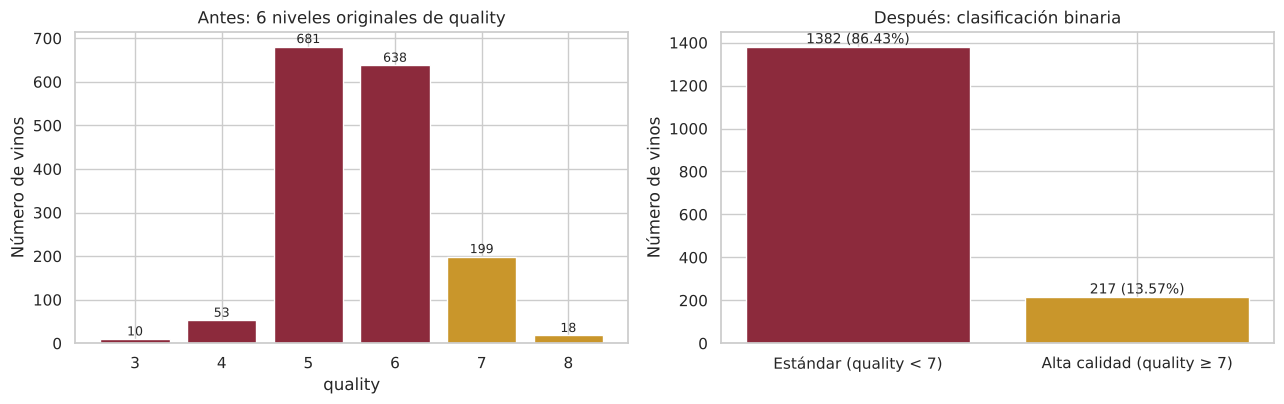

,Dataset completo (n=1599),Sin duplicados (n=1359)
Estándar (quality < 7),1382,1175
Alta calidad (quality ≥ 7),217,184


Proporción de desbalance: 6.4 : 1  →  un clasificador que siempre diga 'estándar' tendría accuracy = 86.43% y recall de alta calidad = 0%


In [5]:
#@title **CÓDIGO:** distribución de quality y de la variable binaria
df["calidad_alta"] = (df["quality"] >= 7).astype(int)
df_nodup["calidad_alta"] = (df_nodup["quality"] >= 7).astype(int)

print(f"quality → media {df['quality'].mean():.3f} · mediana {df['quality'].median():.0f} · "
      f"moda {df['quality'].mode()[0]}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
conteo_q = df["quality"].value_counts().sort_index()
axes[0].bar(conteo_q.index.astype(str), conteo_q.values,
            color=[COLOR_ALTA if q >= 7 else COLOR_STD for q in conteo_q.index])
for x, v in zip(conteo_q.index.astype(str), conteo_q.values):
    axes[0].text(x, v + 8, str(v), ha="center", fontsize=9)
axes[0].set(title="Antes: 6 niveles originales de quality", xlabel="quality", ylabel="Número de vinos")

conteo_b = df["calidad_alta"].value_counts().sort_index()
etiquetas = ["Estándar (quality < 7)", "Alta calidad (quality ≥ 7)"]
axes[1].bar(etiquetas, conteo_b.values, color=PALETA)
for i, v in enumerate(conteo_b.values):
    axes[1].text(i, v + 15, f"{v} ({v / len(df):.2%})", ha="center", fontsize=10)
axes[1].set(title="Después: clasificación binaria", ylabel="Número de vinos")
plt.tight_layout()
plt.show()

tabla_obj = pd.DataFrame({
    "Dataset completo (n=1599)": df["calidad_alta"].value_counts().sort_index(),
    "Sin duplicados (n=1359)": df_nodup["calidad_alta"].value_counts().sort_index()})
tabla_obj.index = etiquetas
display(tabla_obj)
ratio = conteo_b[0] / conteo_b[1]
print(f"Proporción de desbalance: {ratio:.1f} : 1  →  un clasificador que siempre diga "
      f"'estándar' tendría accuracy = {conteo_b[0] / len(df):.2%} y recall de alta calidad = 0%")

## 5. Análisis univariado: asimetría

Se usa el coeficiente de asimetría (*skewness*) con el criterio $|skew| \geq 0.5$ para marcar una variable como asimétrica. La asimetría no es un problema en sí misma: indica qué estadístico describe mejor cada variable (media ± desviación frente a mediana + IQR) y anticipa en qué variables habrá más valores extremos.

,skewness,forma
chlorides,5.680,Asimétrica
residual_sugar,4.541,Asimétrica
sulphates,2.429,Asimétrica
total_sulfur_dioxide,1.516,Asimétrica
free_sulfur_dioxide,1.251,Asimétrica
fixed_acidity,0.983,Asimétrica
alcohol,0.861,Asimétrica
volatile_acidity,0.672,Asimétrica
citric_acid,0.318,Simétrica
pH,0.194,Simétrica


8 / 11 variables asimétricas; simétricas: citric_acid, pH, density


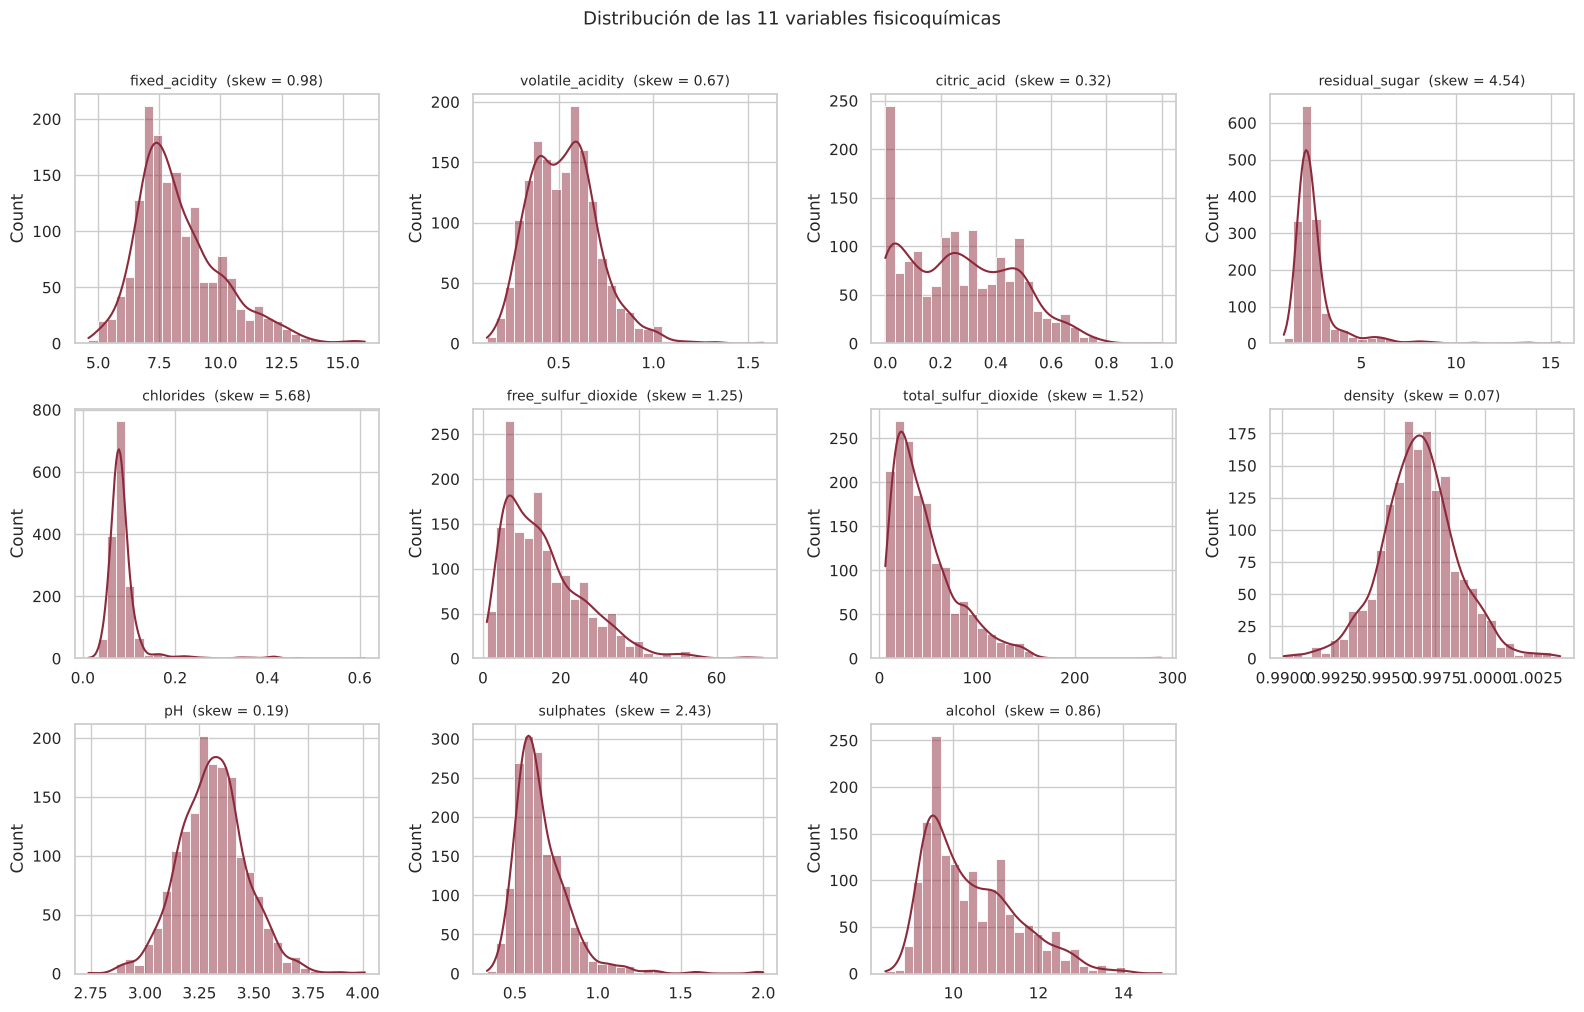

In [6]:
#@title **CÓDIGO:** asimetría e histogramas por variable
skew = df[VARIABLES].skew().sort_values(ascending=False)
tabla_skew = pd.DataFrame({"skewness": skew,
                           "forma": np.where(skew.abs() >= 0.5, "Asimétrica", "Simétrica")})
display(tabla_skew)
print(f"{(skew.abs() >= 0.5).sum()} / {len(VARIABLES)} variables asimétricas; "
      f"simétricas: {', '.join(skew[skew.abs() < 0.5].index)}")

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), VARIABLES):
    sns.histplot(df[col], kde=True, ax=ax, color=COLOR_STD, bins=30)
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})", fontsize=10)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Distribución de las 11 variables fisicoquímicas", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

## 6. Valores atípicos

Se usa el **criterio de Tukey**: un valor es atípico si está por fuera de $[Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$.

,atípicos,% del dataset
residual_sugar,155,9.7
chlorides,112,7.0
sulphates,59,3.7
total_sulfur_dioxide,55,3.4
fixed_acidity,49,3.1
density,45,2.8
pH,35,2.2
free_sulfur_dioxide,30,1.9
volatile_acidity,19,1.2
alcohol,13,0.8


Filas con al menos un atípico: 405 (25.3% del dataset)
Vinos de ALTA calidad que se perderían al filtrar atípicos: 70 de 217 (32.3%)


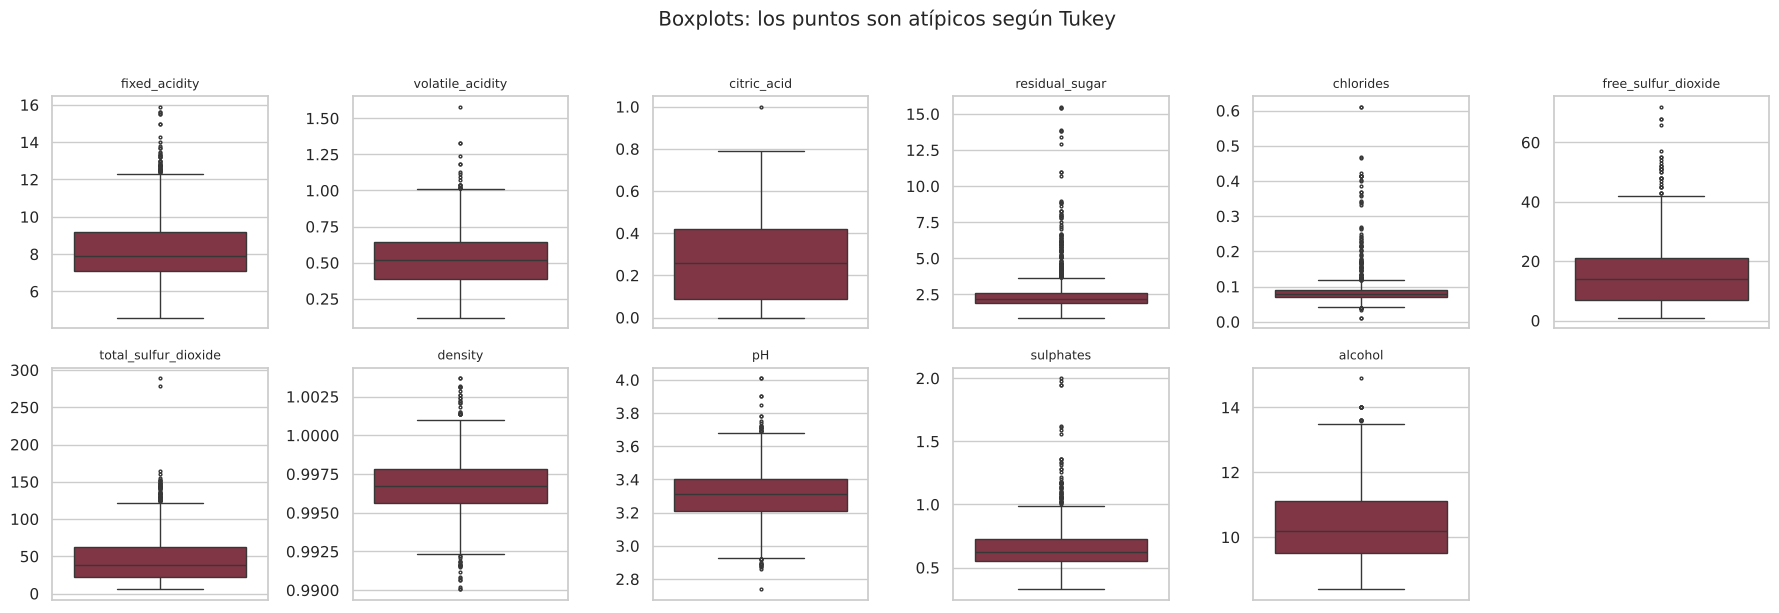

In [7]:
#@title **CÓDIGO:** detección de atípicos (Tukey)
q1, q3 = df[VARIABLES].quantile(0.25), df[VARIABLES].quantile(0.75)
iqr = q3 - q1
es_atipico = (df[VARIABLES] < q1 - 1.5 * iqr) | (df[VARIABLES] > q3 + 1.5 * iqr)

tabla_out = pd.DataFrame({"atípicos": es_atipico.sum(),
                          "% del dataset": (es_atipico.mean() * 100).round(1)}).sort_values("atípicos", ascending=False)
display(tabla_out)

fila_con_atipico = es_atipico.any(axis=1)
alta = df["calidad_alta"] == 1
print(f"Filas con al menos un atípico: {fila_con_atipico.sum()} ({fila_con_atipico.mean():.1%} del dataset)")
print(f"Vinos de ALTA calidad que se perderían al filtrar atípicos: "
      f"{(fila_con_atipico & alta).sum()} de {alta.sum()} ({(fila_con_atipico & alta).sum() / alta.sum():.1%})")

fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for ax, col in zip(axes.ravel(), VARIABLES):
    sns.boxplot(y=df[col], ax=ax, color=COLOR_STD, fliersize=2)
    ax.set_title(col, fontsize=9); ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Boxplots: los puntos son atípicos según Tukey", y=1.02)
plt.tight_layout()
plt.show()

**Decisión: los atípicos no se eliminan.**
1. Son concentraciones químicas válidas dentro de rangos físicamente posibles, no errores de captura.
2. Eliminarlos borraría justamente la señal que buscamos: casi un tercio de los vinos de alta calidad tiene al menos un valor atípico.
3. Con ~1.600 muestras no podemos permitirnos perder una cuarta parte del volumen.

Se manejan en la Parte 2 con **`RobustScaler`** (centra con la mediana y escala con el IQR, por lo que los extremos no distorsionan la escala) en los modelos sensibles a la escala (SVM) y con **modelos basados en árboles**, que solo usan el orden de los valores y por ello no se ven afectados por la magnitud de los extremos.

## 7. Asociación con la calidad y multicolinealidad

- **Pearson** mide asociación **lineal**.
- **Spearman** trabaja con rangos y capta relaciones **monótonas**; es más apropiada con `quality` porque es ordinal y no asumimos linealidad.

Una correlación alta indica **asociación, no causalidad**.

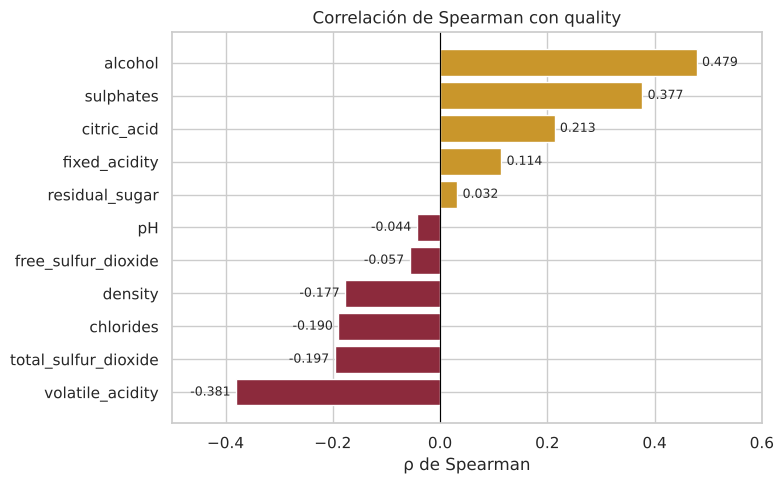

In [8]:
#@title **CÓDIGO:** correlación de Spearman con quality
spearman_q = df[VARIABLES].corrwith(df["quality"], method="spearman").sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(spearman_q.index, spearman_q.values,
        color=[COLOR_ALTA if v > 0 else COLOR_STD for v in spearman_q.values])
for y_pos, v in enumerate(spearman_q.values):
    ax.text(v + (0.01 if v > 0 else -0.01), y_pos, f"{v:.3f}", va="center",
            ha="left" if v > 0 else "right", fontsize=9)
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Correlación de Spearman con quality", xlabel="ρ de Spearman", xlim=(-0.5, 0.6))
plt.tight_layout()
plt.show()

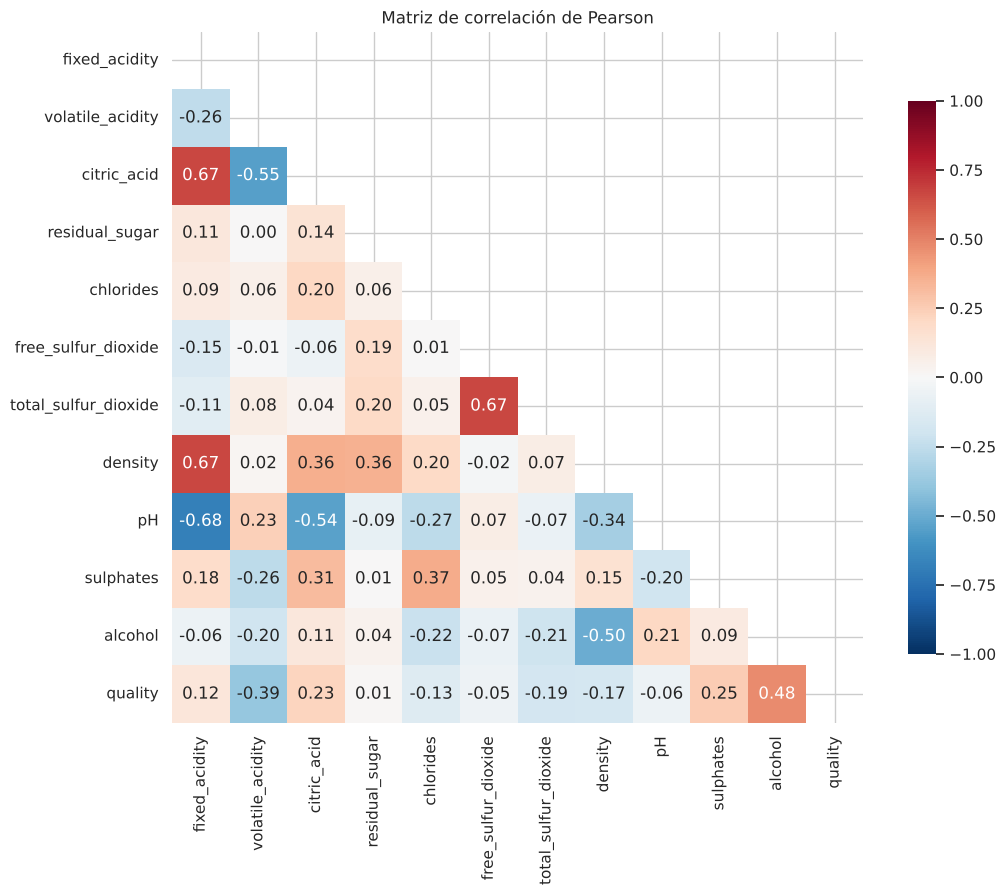

Multicolinealidad detectada (|r| > 0.5):


,variable 1,variable 2,r de Pearson
0,fixed_acidity,pH,-0.683
1,fixed_acidity,citric_acid,0.672
2,fixed_acidity,density,0.668
3,free_sulfur_dioxide,total_sulfur_dioxide,0.668
4,volatile_acidity,citric_acid,-0.552
5,citric_acid,pH,-0.542


In [9]:
#@title **CÓDIGO:** matriz de correlación (Pearson) y pares con |r| > 0.5
corr = df[VARIABLES + ["quality"]].corr()
plt.figure(figsize=(11, 9))
mascara = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .8})
plt.title("Matriz de correlación de Pearson")
plt.tight_layout()
plt.show()

pares = [(a, b, corr.loc[a, b]) for i, a in enumerate(VARIABLES) for b in VARIABLES[i + 1:]
         if abs(corr.loc[a, b]) > 0.5]
tabla_pares = (pd.DataFrame(pares, columns=["variable 1", "variable 2", "r de Pearson"])
               .sort_values("r de Pearson", key=abs, ascending=False).reset_index(drop=True))
print("Multicolinealidad detectada (|r| > 0.5):")
display(tabla_pares)

**Lectura:** `alcohol`, `volatile_acidity`, `sulphates` y `citric_acid` presentan la mayor asociación monótona con `quality`; son **variables candidatas**, no causas confirmadas. Además, varias predictoras están fuertemente relacionadas entre sí (por ejemplo, `fixed_acidity` con `pH`, `citric_acid` y `density`). Esto importa en la Parte 2: el clasificador **Naive Bayes** supone independencia entre variables dentro de cada clase, un supuesto que estos datos violan parcialmente.

## 8. Discriminación estadística por clase

Siguiendo la idea de *discriminación a partir de modelos de las variables*, comparamos la distribución de las cuatro variables candidatas en cada clase. Si las distribuciones se solapan mucho, ningún corte sobre una sola variable separará bien las clases y se justifica un modelo multivariable.

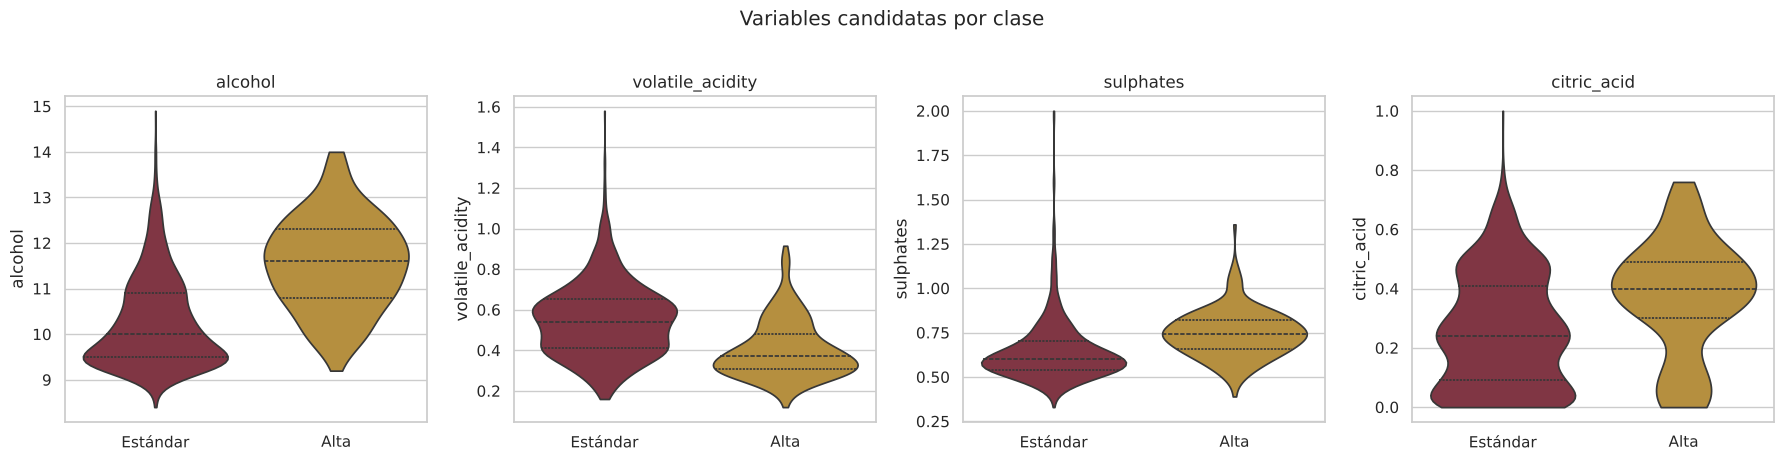

variable,mediana alta,mediana estándar,p-valor,diferencia significativa (α=0.05)
alcohol,11.600,10.000,1.15e-45,Sí
volatile_acidity,0.370,0.540,7.98e-27,Sí
sulphates,0.740,0.600,1.91e-26,Sí
citric_acid,0.400,0.240,1.09e-13,Sí
total_sulfur_dioxide,26.500,40.000,2.18e-10,Sí
chlorides,0.071,0.080,1.87e-09,Sí
density,0.996,0.997,6.84e-09,Sí
fixed_acidity,8.700,7.800,4.70e-06,Sí
free_sulfur_dioxide,11.000,14.000,9.26e-04,Sí
pH,3.270,3.310,1.89e-02,Sí


In [10]:
#@title **CÓDIGO:** distribuciones por clase (sin duplicados)
candidatas = ["alcohol", "volatile_acidity", "sulphates", "citric_acid"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, candidatas):
    sns.violinplot(data=df_nodup, x="calidad_alta", y=col, hue="calidad_alta",
                   palette=PALETA, legend=False, ax=ax, inner="quartile", cut=0)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Estándar", "Alta"])
    ax.set_xlabel(""); ax.set_title(col)
plt.suptitle("Variables candidatas por clase", y=1.02)
plt.tight_layout()
plt.show()

# Prueba de Mann-Whitney U (no paramétrica: no asume normalidad, adecuada por la asimetría)
filas = []
for col in VARIABLES:
    a = df_nodup.loc[df_nodup.calidad_alta == 1, col]
    b = df_nodup.loc[df_nodup.calidad_alta == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    filas.append({"variable": col, "mediana alta": a.median(), "mediana estándar": b.median(),
                  "p-valor": p, "diferencia significativa (α=0.05)": "Sí" if p < 0.05 else "No"})
tabla_mw = pd.DataFrame(filas).sort_values("p-valor").reset_index(drop=True)
display(tabla_mw.style.format({"mediana alta": "{:.3f}", "mediana estándar": "{:.3f}", "p-valor": "{:.2e}"}).hide(axis="index"))

Las medianas difieren de forma estadísticamente significativa en casi todas las variables, pero los diagramas de violín muestran **gran solapamiento** entre clases: una diferencia significativa en la mediana **no** implica que la variable sola permita clasificar bien. Como ilustración (igual que en el ejercicio de clase con `texture_mean`), ajustamos una normal por clase para `alcohol` y vemos dónde la densidad de "alta calidad" supera a la de "estándar":

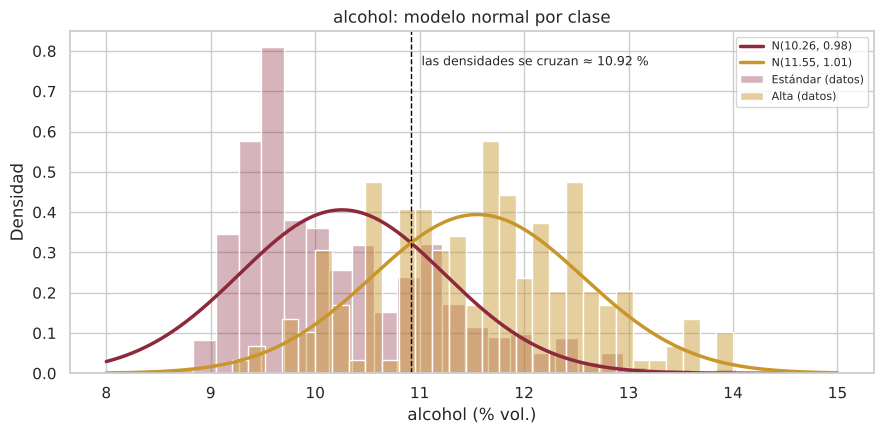

P(alcohol > 10.92 | estándar) = 0.251
P(alcohol > 10.92 | alta)     = 0.735


In [11]:
#@title **CÓDIGO:** densidades normales por clase para alcohol
alc_alta = df_nodup.loc[df_nodup.calidad_alta == 1, "alcohol"]
alc_std = df_nodup.loc[df_nodup.calidad_alta == 0, "alcohol"]
dist_alta = stats.norm(loc=alc_alta.mean(), scale=alc_alta.std())
dist_std = stats.norm(loc=alc_std.mean(), scale=alc_std.std())

x = np.linspace(8, 15, 500)
plt.figure(figsize=(9, 4.5))
sns.histplot(alc_std, stat="density", color=COLOR_STD, alpha=.35, bins=30, label="Estándar (datos)")
sns.histplot(alc_alta, stat="density", color=COLOR_ALTA, alpha=.45, bins=30, label="Alta (datos)")
plt.plot(x, dist_std.pdf(x), color=COLOR_STD, lw=2.5, label=f"N({alc_std.mean():.2f}, {alc_std.std():.2f})")
plt.plot(x, dist_alta.pdf(x), color=COLOR_ALTA, lw=2.5, label=f"N({alc_alta.mean():.2f}, {alc_alta.std():.2f})")
cruce = x[(x > 10) & (dist_alta.pdf(x) > dist_std.pdf(x))][0]
plt.axvline(cruce, ls="--", color="black", lw=1)
plt.text(cruce + 0.1, plt.ylim()[1] * 0.9, f"las densidades se cruzan ≈ {cruce:.2f} %", fontsize=9)
plt.title("alcohol: modelo normal por clase"); plt.xlabel("alcohol (% vol.)"); plt.ylabel("Densidad"); plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"P(alcohol > {cruce:.2f} | estándar) = {1 - dist_std.cdf(cruce):.3f}")
print(f"P(alcohol > {cruce:.2f} | alta)     = {1 - dist_alta.cdf(cruce):.3f}")

Este cálculo compara solo las densidades $p(x \mid clase)$; aún no incorpora que la clase "alta" es mucho menos frecuente (13,5 %). Combinar ambas cosas mediante el teorema de Bayes, y hacerlo con las 11 variables a la vez, es exactamente lo que hace el clasificador **Gaussian Naive Bayes** de la Parte 2.

## 9. Conclusiones de la Parte 1

1. **Integridad:** no hay valores nulos, pero hay **240 duplicados exactos (15,01 %)** que se eliminan antes de modelar → quedan **1.359 vinos únicos**.
2. **Desbalance:** solo el **13,6 %** de los vinos es de alta calidad (≈ 6,4 : 1). La *accuracy* sola no sirve para evaluar.
3. **Atípicos como señal, no ruido:** eliminarlos costaría el 32,3 % de los vinos de alta calidad; se conservan y se manejan con escalado robusto y árboles.
4. **Variables candidatas:** `alcohol`, `volatile_acidity`, `sulphates` y `citric_acid`; las clases se solapan, lo que justifica un modelo multivariable.

**Plan para la Parte 2 (definido en la Entrega 1):** limpieza → partición → escalado robusto → manejo del desbalance → entrenamiento de modelos → evaluación con precision, recall, F1, matriz de confusión y ROC-AUC.

---
# **PARTE 2. CLASIFICACIÓN CON MODELOS SUPERVISADOS (Entrega 2)**

## 10. Planteamiento del problema supervisado y métricas

En aprendizaje **supervisado** contamos con ejemplos etiquetados $(x, y)$ y buscamos aprender una función

$$\hat{f}: x \rightarrow y, \qquad x = (x_1, \dots, x_{11}) \text{ (mediciones fisicoquímicas)}, \quad y \in \{0, 1\}$$

que **generalice** a vinos nuevos cuya etiqueta desconocemos. Como $y$ es discreta, es un problema de **clasificación binaria**. La **clase positiva** es `1 = alta calidad`.

**Matriz de confusión** (filas = clase real, columnas = predicción):

| | Predice estándar (0) | Predice alta (1) |
|---|---|---|
| **Real estándar (0)** | TN (verdadero negativo) | FP (falso positivo) |
| **Real alta (1)** | FN (falso negativo) | TP (verdadero positivo) |

| Métrica | Fórmula | Pregunta que responde en este problema |
|---|---|---|
| Accuracy | $\frac{TP+TN}{TP+TN+FP+FN}$ | ¿Qué fracción total acierto? (engañosa con desbalance) |
| Precision | $\frac{TP}{TP+FP}$ | De los vinos que el modelo marca como "alta", ¿cuántos lo son? |
| Recall (sensibilidad, TPR) | $\frac{TP}{TP+FN}$ | De los vinos realmente "alta", ¿cuántos detecta? |
| Especificidad (TNR) | $\frac{TN}{TN+FP}$ | De los vinos estándar, ¿cuántos reconoce como estándar? |
| **F1** | $2\cdot\frac{P \cdot R}{P + R}$ | Equilibrio entre precision y recall (media armónica) |
| ROC-AUC | área bajo la curva TPR vs. FPR | ¿Qué tan bien **ordena** el modelo (positivo por encima de negativo), sin fijar umbral? |
| PR-AUC (*average precision*) | área bajo la curva precision vs. recall | Igual que la anterior, pero centrada en la clase minoritaria; su valor de azar es la prevalencia (≈ 0,135) |

**Métrica principal: F1 de la clase "alta calidad".** Con 86 % de vinos estándar, la *accuracy* premia al modelo que nunca detecta vinos buenos. F1 solo es alto si el modelo **encuentra** los vinos de alta calidad (recall) **sin** llenar la lista de falsos positivos (precision). Para una bodega ambos errores cuestan: un FN es un vino premium vendido como estándar (pérdida de margen) y un FP es un vino estándar enviado como premium (riesgo de reputación).

## 11. Preparación: partición de los datos y protocolo de validación

1. Se parte del dataset **sin duplicados** (1.359 vinos) para evitar fuga de información.
2. Se reserva un **20 % como conjunto de test**, con partición **estratificada** (conserva el 13,5 % de positivos). El test **no se usa** para ninguna decisión: se consulta **una sola vez** al final.
3. El 80 % restante es el **conjunto de desarrollo**. Toda decisión (hiperparámetros, modelo, umbral) se toma con **validación cruzada estratificada de 5 folds** dentro de él: en cada fold el modelo se entrena con 4/5 y se valida con el 1/5 restante, de modo que cada vino de desarrollo actúa como validación exactamente una vez.
4. Todo preprocesamiento (escalado) va dentro de un `Pipeline`, que se ajusta **solo** con los datos de entrenamiento de cada fold.

In [12]:
#@title **CÓDIGO:** variables X, y y partición desarrollo / test
X = df_nodup[VARIABLES].copy()
y = df_nodup["calidad_alta"].copy()

X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)

resumen_part = pd.DataFrame({
    "vinos": [len(y), len(y_dev), len(y_test)],
    "alta calidad (1)": [y.sum(), y_dev.sum(), y_test.sum()],
    "estándar (0)": [(y == 0).sum(), (y_dev == 0).sum(), (y_test == 0).sum()],
    "% alta calidad": [y.mean() * 100, y_dev.mean() * 100, y_test.mean() * 100]},
    index=["Total (sin duplicados)", "Desarrollo (80 %)", "Test (20 %)"])
display(resumen_part.round(2))

# Comprobación: ningún vino del test aparece en desarrollo
print("Vinos compartidos entre desarrollo y test:",
      len(pd.merge(X_dev, X_test, how="inner", on=VARIABLES)))

,vinos,alta calidad (1),estándar (0),% alta calidad
Total (sin duplicados),1359,184,1175,13.54
Desarrollo (80 %),1087,147,940,13.52
Test (20 %),272,37,235,13.60


Vinos compartidos entre desarrollo y test: 0


In [13]:
#@title **CÓDIGO:** esquemas de validación cruzada y funciones auxiliares
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)            # ajuste de hiperparámetros
CV_REP = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED + 1)  # comparación final (15 folds)

def especificidad(y_true, y_pred):
    return recall_score(y_true, y_pred, pos_label=0, zero_division=0)

SCORING = {"F1": make_scorer(f1_score, zero_division=0),
           "Recall": make_scorer(recall_score, zero_division=0),
           "Precision": make_scorer(precision_score, zero_division=0),
           "Especificidad": make_scorer(especificidad),
           "Accuracy": "accuracy",
           "ROC_AUC": "roc_auc",
           "PR_AUC": "average_precision"}

def resumen_cv(nombre, modelo, X_, y_, cv, metricas=("F1", "Recall", "Precision", "Especificidad",
                                                    "Accuracy", "ROC_AUC", "PR_AUC")):
    """Validación cruzada: devuelve media y desviación estándar de cada métrica entre folds."""
    sc = cross_validate(modelo, X_, y_, cv=cv, scoring={m: SCORING[m] for m in metricas},
                        return_train_score=True, n_jobs=-1)
    fila = {"Modelo": nombre}
    for m in metricas:
        fila[m] = sc[f"test_{m}"].mean()
        fila[f"{m} (std)"] = sc[f"test_{m}"].std()
    fila["F1 train"] = sc["train_F1"].mean()
    return fila, sc

def metricas_pred(nombre, y_true, y_pred, score=None):
    """Métricas sobre un conjunto concreto a partir de predicciones (y puntajes, si existen)."""
    fila = {"Modelo": nombre,
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Especificidad": especificidad(y_true, y_pred),
            "Accuracy": accuracy_score(y_true, y_pred)}
    if score is not None:
        fila["ROC_AUC"] = roc_auc_score(y_true, score)
        fila["PR_AUC"] = average_precision_score(y_true, score)
    return fila

def puntaje(modelo, X_):
    """Puntaje continuo de la clase positiva (probabilidad o distancia a la frontera)."""
    if hasattr(modelo, "predict_proba"):
        try:
            return modelo.predict_proba(X_)[:, 1]
        except AttributeError:
            pass
    return modelo.decision_function(X_)

COLS_TABLA = ["F1", "F1 (std)", "Recall", "Precision", "Especificidad", "Accuracy", "ROC_AUC", "PR_AUC", "F1 train"]
print("Listo: CV5 =", CV5, "\n       CV_REP =", CV_REP)

Listo: CV5 = StratifiedKFold(n_splits=5, random_state=21, shuffle=True) 
       CV_REP = RepeatedStratifiedKFold(n_repeats=3, n_splits=5, random_state=22)


## 12. Líneas base: clasificador trivial y regla simple

Un modelo solo vale la pena si supera alternativas sencillas. Se usan dos líneas base:

- **`DummyClassifier`** (siempre predice la clase mayoritaria): materializa el problema de la *accuracy* descrito en la Entrega 1.
- **Regla simple sobre `alcohol`**: "si `alcohol` ≥ *t*, es alta calidad". Es la regla manual que un enólogo podría proponer. Para evaluarla con honestidad, el umbral *t* **se aprende dentro de cada fold de entrenamiento** (el que maximiza F1) y se evalúa en el fold de validación, exactamente como un modelo.

In [14]:
#@title **CÓDIGO:** regla de un umbral implementada como estimador de scikit-learn
from sklearn.base import BaseEstimator, ClassifierMixin

class ReglaUmbral(ClassifierMixin, BaseEstimator):
    """Predice 1 si X[variable] >= t. El umbral t se elige en fit maximizando F1 en entrenamiento."""
    def __init__(self, variable="alcohol"):
        self.variable = variable

    def fit(self, X_, y_):
        x = np.asarray(X_[self.variable]); y_ = np.asarray(y_)
        candidatos = np.unique(x)
        f1s = [f1_score(y_, (x >= t).astype(int), zero_division=0) for t in candidatos]
        self.umbral_ = candidatos[int(np.argmax(f1s))]
        self.classes_ = np.array([0, 1])
        return self

    def decision_function(self, X_):
        return np.asarray(X_[self.variable], dtype=float)

    def predict(self, X_):
        return (self.decision_function(X_) >= self.umbral_).astype(int)

lineas_base = {"Dummy (siempre 'estándar')": DummyClassifier(strategy="most_frequent"),
               "Regla: alcohol ≥ t": ReglaUmbral("alcohol")}
filas_base = []
for nombre, modelo in lineas_base.items():
    metr = ("F1", "Recall", "Precision", "Especificidad", "Accuracy") if "Dummy" in nombre else \
           ("F1", "Recall", "Precision", "Especificidad", "Accuracy", "ROC_AUC", "PR_AUC")
    fila, _ = resumen_cv(nombre, modelo, X_dev, y_dev, CV5, metricas=metr)
    filas_base.append(fila)
tabla_base = pd.DataFrame(filas_base).set_index("Modelo").reindex(columns=COLS_TABLA)
display(tabla_base.round(3))
print(f"Umbral aprendido con todo el conjunto de desarrollo: alcohol ≥ "
      f"{ReglaUmbral('alcohol').fit(X_dev, y_dev).umbral_} % vol.")

,F1,F1 (std),Recall,Precision,Especificidad,Accuracy,ROC_AUC,PR_AUC,F1 train
Modelo,,,,,,,,,
Dummy (siempre 'estándar'),0.000,0.000,0.000,0.000,1.000,0.865,NaN,NaN,0.000
Regla: alcohol ≥ t,0.478,0.042,0.509,0.458,0.903,0.850,0.823,0.404,0.479


Umbral aprendido con todo el conjunto de desarrollo: alcohol ≥ 11.6 % vol.


El clasificador trivial tiene **accuracy ≈ 0,865 con F1 = 0**: confirma que la accuracy no sirve como métrica principal. La regla de una sola variable ya detecta vinos de alta calidad, pero con muchos falsos positivos (precision baja). **Cualquier modelo propuesto debe superar el F1 de esta regla**; de lo contrario no aportaría nada frente a una regla manual.

## 13. Modelos con configuración por defecto

Se evalúan los modelos vistos en clase con sus hiperparámetros por defecto, más **Gradient Boosting**, que se propuso en la Entrega 1 como segundo modelo basado en árboles:

| Modelo | Idea | Necesita escalado |
|---|---|---|
| **Gaussian Naive Bayes (GNB)** | Teorema de Bayes + supone cada variable normal e independiente dentro de cada clase | No |
| **Árbol de decisión (DT)** | Reglas "si-entonces" que dividen el espacio para reducir la impureza (Gini) | No |
| **Random Forest (RF)** | Muchos árboles con muestras *bootstrap* y subconjuntos aleatorios de variables; vota la mayoría | No |
| **SVM (kernel RBF)** | Frontera de máximo margen; el kernel permite fronteras no lineales | **Sí** (usa distancias) |
| **Gradient Boosting (GB)** | Árboles pequeños en secuencia; cada uno corrige los errores de los anteriores | No |

La SVM se combina con **`RobustScaler`** dentro de un `Pipeline`, según el plan de la Entrega 1.

In [15]:
#@title **CÓDIGO:** modelos por defecto evaluados con CV estratificada de 5 folds
modelos_defecto = {
    "GNB": GaussianNB(),
    "Árbol de decisión": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(random_state=SEED, n_jobs=-1),
    "SVM (RBF)": Pipeline([("escalado", RobustScaler()), ("svc", SVC(random_state=SEED))]),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED)}

filas_def = []
for nombre, modelo in modelos_defecto.items():
    fila, _ = resumen_cv(nombre, modelo, X_dev, y_dev, CV5)
    filas_def.append(fila)
tabla_defecto = pd.concat([tabla_base, pd.DataFrame(filas_def).set_index("Modelo").reindex(columns=COLS_TABLA)])
display(tabla_defecto.round(3))

,F1,F1 (std),Recall,Precision,Especificidad,Accuracy,ROC_AUC,PR_AUC,F1 train
Modelo,,,,,,,,,
Dummy (siempre 'estándar'),0.000,0.000,0.000,0.000,1.000,0.865,NaN,NaN,0.000
Regla: alcohol ≥ t,0.478,0.042,0.509,0.458,0.903,0.850,0.823,0.404,0.479
GNB,0.523,0.048,0.658,0.441,0.869,0.841,0.851,0.473,0.556
Árbol de decisión,0.433,0.026,0.449,0.423,0.902,0.841,0.675,0.264,1.000
Random Forest,0.419,0.053,0.327,0.632,0.966,0.880,0.870,0.577,1.000
SVM (RBF),0.271,0.142,0.169,0.692,0.995,0.883,0.845,0.562,0.426
Gradient Boosting,0.476,0.055,0.421,0.576,0.949,0.878,0.869,0.548,0.889


**Lectura de la tabla.** Observe la columna `F1 train`: el árbol y el Random Forest por defecto obtienen F1 = 1,0 en entrenamiento (memorizan los datos: crecen hasta hojas puras), pero mucho menos en validación → **sobreajuste**. La SVM y el Gradient Boosting por defecto tienen precision razonable pero **recall bajo**: con un 13,5 % de positivos, la frontera se desplaza hacia la clase mayoritaria y "deja pasar" vinos buenos. Esto motiva dos acciones: **controlar la complejidad** (hiperparámetros) y **manejar el desbalance** (`class_weight="balanced"`, que pesa cada error de la clase minoritaria ≈ 6,4 veces más).

### ¿Por qué validación cruzada y no una sola partición de validación?

En clase usamos una partición única *train* (60 %) / *validación* (20 %). Aquí la validación tendría solo **37 vinos de alta calidad**: cada acierto o fallo cambia el recall en ~2,7 puntos. Para medir cuánto cambia la conclusión según la partición, repetimos la partición 60/20 del conjunto de desarrollo con 30 semillas distintas y medimos el F1 de validación de GNB y de Random Forest (ambos por defecto).

,mean,std,min,max
Modelo,,,,
GNB,0.530,0.053,0.425,0.683
Random Forest,0.423,0.075,0.291,0.571


GNB: F1 entre 0.425 y 0.683 (rango 0.258); con la semilla 21 de clase obtiene 0.683 → puesto 1 de 30 (media 0.530)
Random Forest: F1 entre 0.291 y 0.571 (rango 0.281); con la semilla 21 de clase obtiene 0.392 → puesto 22 de 30 (media 0.423)


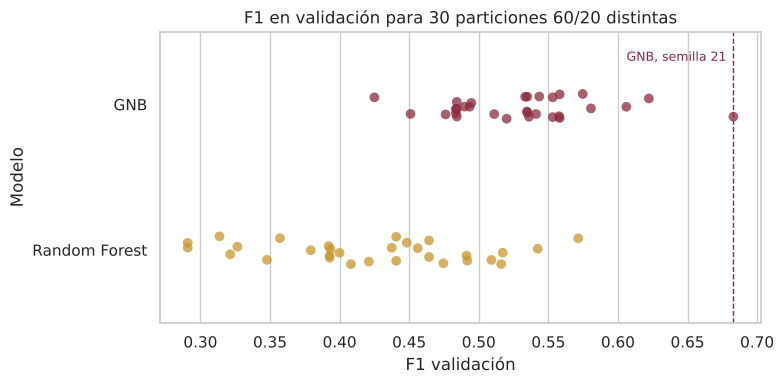

In [16]:
#@title **CÓDIGO:** variabilidad del F1 con una sola partición train / validación
filas_var = []
for semilla in range(30):
    X_tr, X_va, y_tr, y_va = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=semilla)
    for nombre in ["GNB", "Random Forest"]:
        m = clone(modelos_defecto[nombre]).fit(X_tr, y_tr)
        filas_var.append({"semilla": semilla, "Modelo": nombre, "F1 validación": f1_score(y_va, m.predict(X_va))})
var_split = pd.DataFrame(filas_var)

display(var_split.groupby("Modelo")["F1 validación"].describe()[["mean", "std", "min", "max"]].round(3))
ancho = var_split.pivot(index="semilla", columns="Modelo", values="F1 validación")
for nombre in ["GNB", "Random Forest"]:
    v = ancho[nombre]
    puesto = int((v > v.loc[SEED]).sum()) + 1
    print(f"{nombre}: F1 entre {v.min():.3f} y {v.max():.3f} (rango {v.max() - v.min():.3f}); "
          f"con la semilla {SEED} de clase obtiene {v.loc[SEED]:.3f} → puesto {puesto} de 30 (media {v.mean():.3f})")

plt.figure(figsize=(8, 4))
sns.stripplot(data=var_split, x="F1 validación", y="Modelo", hue="Modelo",
              palette=[COLOR_STD, COLOR_ALTA], size=7, alpha=.75, legend=False)
plt.axvline(ancho.loc[SEED, "GNB"], color=COLOR_STD, ls="--", lw=1)
plt.text(ancho.loc[SEED, "GNB"] - 0.005, -0.3, f"GNB, semilla {SEED}", ha="right", fontsize=9, color=COLOR_STD)
plt.title("F1 en validación para 30 particiones 60/20 distintas")
plt.tight_layout()
plt.show()

Con una sola partición, el F1 de **un mismo modelo** cambia más de 0,25 puntos según qué vinos caigan en validación. La semilla 21 de clase resulta ser, por azar, la partición **más favorable de las 30 para GNB** (0,683 frente a una media de 0,530): decidir con ella sobreestimaría GNB en ~0,15. Por eso todas las decisiones de este notebook se toman con validación cruzada estratificada (cada vino de desarrollo se usa como validación), y la comparación final usa **5 folds × 3 repeticiones**. Además, el Random Forest **por defecto** queda por debajo de GNB: sin controlar su complejidad ni el desbalance, sobreajusta (F1 train = 1,0) y su recall es bajo; la sección 14 corrige ambas cosas.

## 14. Ajuste de hiperparámetros por modelo

Para cada modelo se explora primero el hiperparámetro que controla su complejidad (curvas **entrenamiento vs. validación**, como en los ejercicios de sobreajuste de clase) y luego se hace una búsqueda en rejilla (`GridSearchCV`) con los 5 folds estratificados, optimizando **F1**. `GridSearchCV` reentrena al final la mejor configuración con todo el conjunto de desarrollo.

In [17]:
#@title **CÓDIGO:** funciones de apoyo para curvas y búsquedas
def curva_validacion(modelo, parametro, valores, etiquetas=None, titulo="", xlabel=None, ax=None):
    tr, va = validation_curve(modelo, X_dev, y_dev, param_name=parametro, param_range=valores,
                              cv=CV5, scoring=SCORING["F1"], n_jobs=-1)
    etiquetas = etiquetas or [str(v) for v in valores]
    pos = np.arange(len(valores))
    ax = ax or plt.gca()
    for datos, nombre, color in [(tr, "Entrenamiento", COLOR_STD), (va, "Validación (CV)", COLOR_ALTA)]:
        ax.plot(pos, datos.mean(axis=1), "o-", color=color, label=nombre, lw=2)
        ax.fill_between(pos, datos.mean(axis=1) - datos.std(axis=1), datos.mean(axis=1) + datos.std(axis=1),
                        color=color, alpha=.15)
    mejor = int(np.argmax(va.mean(axis=1)))
    ax.axvline(pos[mejor], color="gray", ls=":", lw=1)
    ax.set_xticks(pos); ax.set_xticklabels(etiquetas)
    ax.set(title=titulo, xlabel=xlabel or parametro, ylabel="F1 (clase alta)", ylim=(0, 1.05))
    ax.legend(loc="lower right")
    return pd.DataFrame({"valor": etiquetas, "F1 train": tr.mean(axis=1), "F1 validación": va.mean(axis=1),
                         "std validación": va.std(axis=1)})

busquedas = {}
def buscar(nombre, modelo, rejilla):
    t0 = time.perf_counter()
    gs = GridSearchCV(modelo, rejilla, cv=CV5, scoring=SCORING["F1"], n_jobs=-1, return_train_score=True)
    gs.fit(X_dev, y_dev)
    busquedas[nombre] = gs
    i = gs.best_index_
    n_conf = len(gs.cv_results_["params"])
    print(f"{nombre}: {n_conf} configuraciones × 5 folds = {n_conf * 5} entrenamientos "
          f"({time.perf_counter() - t0:.1f} s)")
    print("  Mejores hiperparámetros:", {k: (type(v).__name__ if hasattr(v, "fit") else v)
                                        for k, v in gs.best_params_.items()})
    print(f"  F1 validación (CV) = {gs.best_score_:.3f} ± {gs.cv_results_['std_test_score'][i]:.3f} | "
          f"F1 entrenamiento = {gs.cv_results_['mean_train_score'][i]:.3f}")
    return gs

### 14.1 Gaussian Naive Bayes

Para un vino nuevo $x$, GNB estima la probabilidad de cada clase con el **teorema de Bayes** y elige la mayor:

$$P(c \mid x) = \frac{p(x \mid c)\,P(c)}{p(x)} \;\propto\; P(c)\prod_{j=1}^{11} \mathcal{N}(x_j;\, \mu_{c,j},\, \sigma_{c,j})$$

- $P(c)$ (*prior*): frecuencia de cada clase en entrenamiento (≈ 0,865 y 0,135).
- $p(x_j \mid c)$: densidad **normal** de cada variable dentro de cada clase (media y desviación estimadas de los datos), como en la sección 8.
- Es "ingenuo" (*naive*) porque multiplica las densidades, es decir, **supone independencia** entre variables dentro de cada clase. En estos datos el supuesto se viola (sección 7: `fixed_acidity` ↔ `pH`, `citric_acid`, `density`), y además varias variables son asimétricas (no normales). Aun así es una referencia rápida e interpretable.
- Su único hiperparámetro, `var_smoothing`, suma una pequeña fracción de la varianza máxima a todas las varianzas para estabilizar el cálculo.

In [18]:
#@title **CÓDIGO:** GNB: parámetros aprendidos y búsqueda
gnb_demo = GaussianNB().fit(X_dev, y_dev)
print("Priors P(c):", dict(zip(["estándar", "alta"], gnb_demo.class_prior_.round(3))))
param_gnb = pd.DataFrame({"μ estándar": gnb_demo.theta_[0], "μ alta": gnb_demo.theta_[1],
                          "σ estándar": np.sqrt(gnb_demo.var_[0]), "σ alta": np.sqrt(gnb_demo.var_[1])},
                         index=VARIABLES)
display(param_gnb.loc[candidatas].round(3))

gs_gnb = buscar("GNB", GaussianNB(), {"var_smoothing": np.logspace(-9, -1, 9)})

Priors P(c): {'estándar': np.float64(0.865), 'alta': np.float64(0.135)}


,μ estándar,μ alta,σ estándar,σ alta
alcohol,10.243,11.510,0.967,0.994
volatile_acidity,0.549,0.401,0.182,0.138
sulphates,0.646,0.750,0.162,0.133
citric_acid,0.257,0.378,0.192,0.181


GNB: 9 configuraciones × 5 folds = 45 entrenamientos (0.3 s)
  Mejores hiperparámetros: {'var_smoothing': np.float64(1e-08)}
  F1 validación (CV) = 0.533 ± 0.036 | F1 entrenamiento = 0.549


### 14.2 Árbol de decisión

El árbol divide los datos con preguntas del tipo "¿`alcohol` ≤ 11,55?" eligiendo en cada nodo la división que más reduce la **impureza de Gini** $G = 1 - \sum_c p_c^2$ (o la entropía). Si crece sin límite, termina con hojas puras que memorizan el entrenamiento. Se controla con:

- `max_depth`: profundidad máxima.
- `min_samples_leaf`: mínimo de vinos por hoja (evita reglas basadas en uno o dos vinos).
- `class_weight="balanced"`: compensa el desbalance en el cálculo de la impureza.

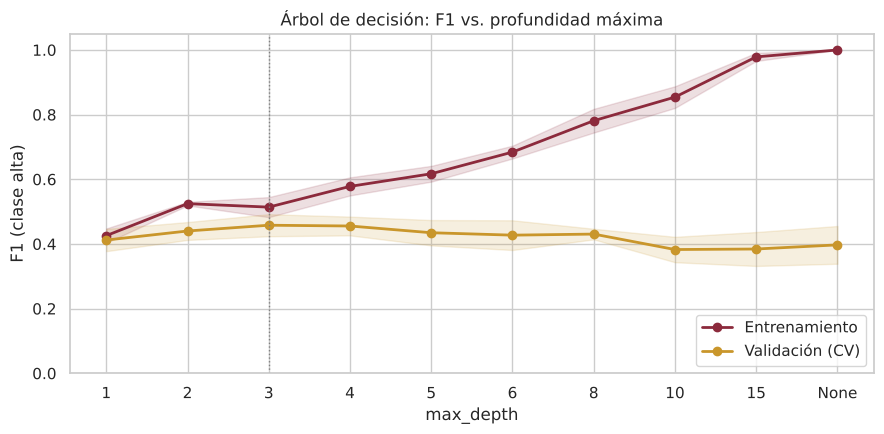

,0,1,2,3,4,5,6,7,8,9
valor,1,2,3,4,5,6,8,10,15,None
F1 train,0.426,0.525,0.514,0.578,0.617,0.684,0.781,0.854,0.979,1.0
F1 validación,0.412,0.44,0.458,0.456,0.435,0.427,0.431,0.383,0.384,0.397
std validación,0.034,0.028,0.034,0.029,0.039,0.046,0.016,0.039,0.052,0.058


In [19]:
#@title **CÓDIGO:** árbol: curva de complejidad (max_depth)
plt.figure(figsize=(9, 4.5))
curva_dt = curva_validacion(DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
                            "max_depth", [1, 2, 3, 4, 5, 6, 8, 10, 15, None],
                            titulo="Árbol de decisión: F1 vs. profundidad máxima", xlabel="max_depth")
plt.tight_layout(); plt.show()
display(curva_dt.round(3).T)

El F1 de validación es máximo con profundidad 3–4 (≈ 0,46). A partir de ahí el F1 de entrenamiento sigue subiendo hasta 1,0 (árbol sin límite) mientras el de validación baja hasta ≈ 0,38–0,40: el árbol **sobreajusta** (memoriza el entrenamiento). Con profundidad 1 ambos son bajos (≈ 0,41–0,43): **subajuste**. La búsqueda combina profundidad, tamaño mínimo de hoja, criterio y peso de clases; `min_samples_leaf` permite árboles más profundos sin hojas de uno o dos vinos:

In [20]:
#@title **CÓDIGO:** árbol: búsqueda en rejilla
gs_dt = buscar("Árbol de decisión", DecisionTreeClassifier(random_state=SEED),
               {"max_depth": [2, 3, 4, 5, 6, 8, None],
                "min_samples_leaf": [1, 5, 10, 20],
                "criterion": ["gini", "entropy"],
                "class_weight": [None, "balanced"]})

Árbol de decisión: 112 configuraciones × 5 folds = 560 entrenamientos (3.1 s)
  Mejores hiperparámetros: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 20}
  F1 validación (CV) = 0.477 ± 0.035 | F1 entrenamiento = 0.582


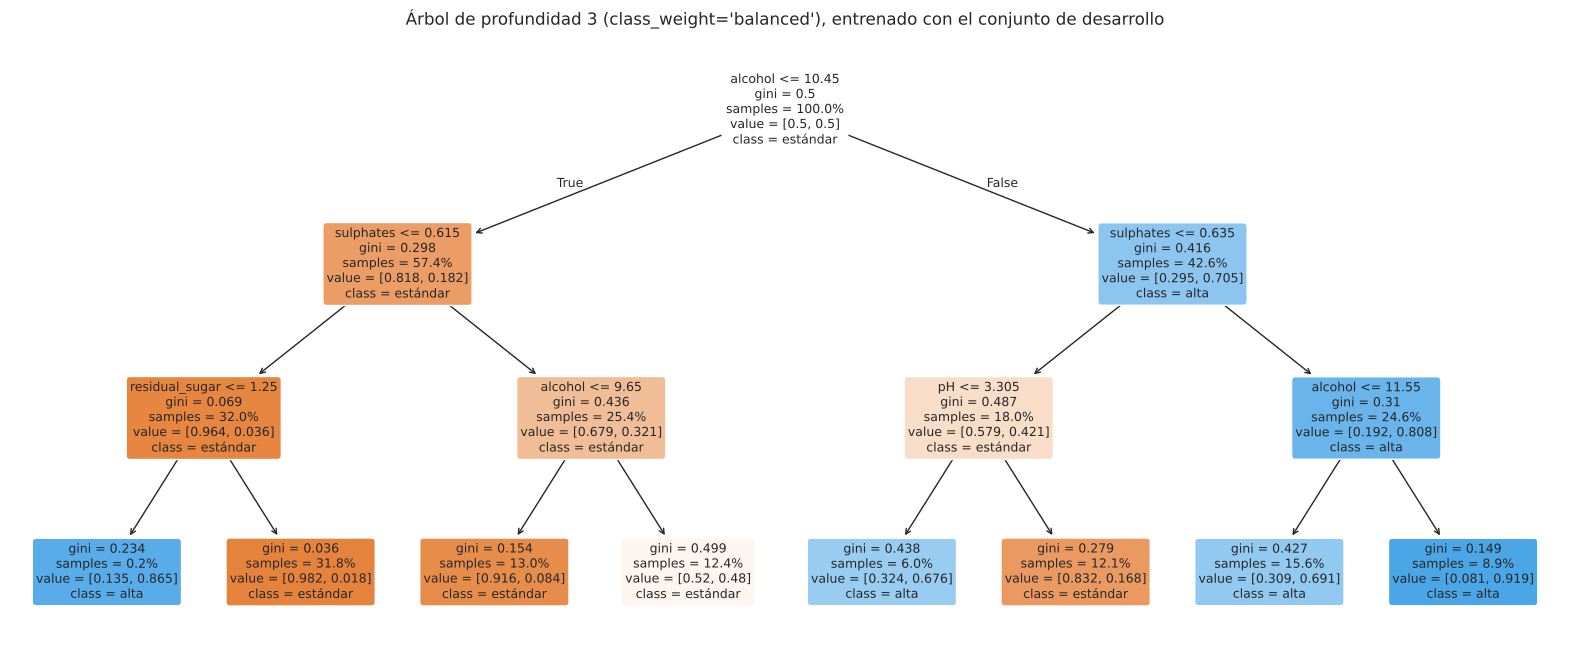

In [21]:
#@title **CÓDIGO:** visualización de un árbol interpretable (profundidad 3)
arbol_vis = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=SEED).fit(X_dev, y_dev)
plt.figure(figsize=(20, 8))
plot_tree(arbol_vis, feature_names=VARIABLES, class_names=["estándar", "alta"], filled=True,
          rounded=True, fontsize=9, proportion=True, impurity=True)
plt.title("Árbol de profundidad 3 (class_weight='balanced'), entrenado con el conjunto de desarrollo")
plt.show()

El árbol de profundidad 3 se muestra por **legibilidad**: sus primeras divisiones usan `alcohol`, `sulphates` y `volatile_acidity`, las mismas variables que destacaron en el EDA. Con `proportion=True`, `samples` es la fracción de vinos que llega a cada nodo y `value` las proporciones ponderadas de cada clase.

### 14.3 Random Forest

Un Random Forest entrena muchos árboles, cada uno con una **muestra bootstrap** (con reemplazo) y considerando en cada división solo un **subconjunto aleatorio de variables** (`max_features`). Al promediar árboles distintos entre sí se **reduce la varianza** del árbol individual sin aumentar mucho el sesgo.

- `n_estimators`: número de árboles (más árboles → predicción más estable, más tiempo; no causa sobreajuste por sí mismo).
- `max_depth`, `min_samples_leaf`: complejidad de cada árbol.
- `max_features`: variables candidatas en cada división (`"sqrt"` → $\sqrt{11} \approx 3$).
- `class_weight="balanced_subsample"`: pesos de clase recalculados en cada muestra bootstrap.

,n_estimators,F1 train,F1 validación,std validación,tiempo CV (s)
0,10,0.797,0.526,0.079,0.322
1,25,0.811,0.548,0.058,0.535
2,50,0.828,0.561,0.048,0.775
3,100,0.835,0.552,0.070,1.425
4,200,0.830,0.544,0.069,2.846
5,300,0.829,0.536,0.069,4.129
6,500,0.826,0.551,0.068,6.665


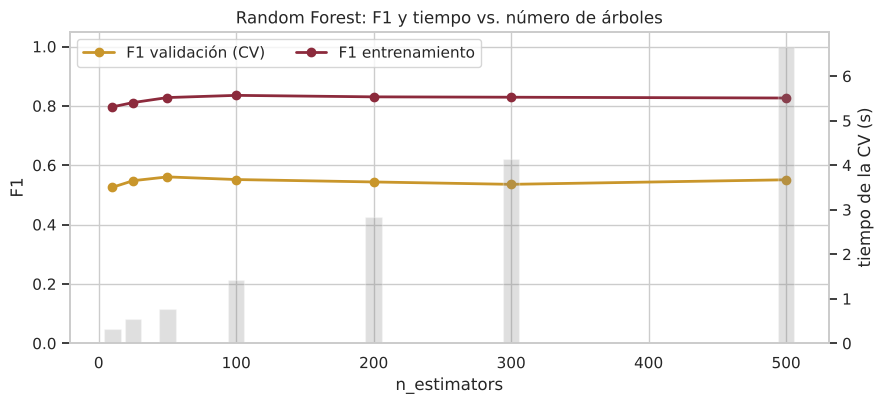

In [22]:
#@title **CÓDIGO:** Random Forest: efecto del número de árboles
filas_rf = []
for n in [10, 25, 50, 100, 200, 300, 500]:
    rf_n = RandomForestClassifier(n_estimators=n, min_samples_leaf=5, class_weight="balanced_subsample",
                                  random_state=SEED, n_jobs=-1)
    t0 = time.perf_counter()
    sc = cross_validate(rf_n, X_dev, y_dev, cv=CV5, scoring=SCORING["F1"], return_train_score=True)
    filas_rf.append({"n_estimators": n, "F1 train": sc["train_score"].mean(),
                     "F1 validación": sc["test_score"].mean(), "std validación": sc["test_score"].std(),
                     "tiempo CV (s)": time.perf_counter() - t0})
curva_rf = pd.DataFrame(filas_rf)
display(curva_rf.round(3))

fig, ax1 = plt.subplots(figsize=(9, 4.2))
ax1.plot(curva_rf["n_estimators"], curva_rf["F1 validación"], "o-", color=COLOR_ALTA, lw=2, label="F1 validación (CV)")
ax1.plot(curva_rf["n_estimators"], curva_rf["F1 train"], "o-", color=COLOR_STD, lw=2, label="F1 entrenamiento")
ax1.set(xlabel="n_estimators", ylabel="F1", ylim=(0, 1.05), title="Random Forest: F1 y tiempo vs. número de árboles")
ax2 = ax1.twinx(); ax2.grid(False)
ax2.bar(curva_rf["n_estimators"], curva_rf["tiempo CV (s)"], width=12, alpha=.25, color="gray", label="tiempo (s)")
ax2.set_ylabel("tiempo de la CV (s)")
ax1.legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

Desde ~50 árboles las diferencias de F1 de validación (≤ 0,03) son menores que la desviación entre folds (≈ 0,07): **más árboles no mejoran ni empeoran el F1** (no causan sobreajuste), pero sí estabilizan las probabilidades promediadas, lo que importa para el umbral de la sección 16; el tiempo crece de forma lineal. Se fija **`n_estimators = 300`** como compromiso y se ajusta el resto:

In [23]:
#@title **CÓDIGO:** Random Forest: búsqueda en rejilla (n_estimators = 300)
gs_rf = buscar("Random Forest", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
               {"max_depth": [8, None],
                "min_samples_leaf": [1, 3, 5],
                "max_features": ["sqrt", 0.5],
                "class_weight": [None, "balanced_subsample"]})

Random Forest: 24 configuraciones × 5 folds = 120 entrenamientos (44.9 s)
  Mejores hiperparámetros: {'class_weight': 'balanced_subsample', 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 5}
  F1 validación (CV) = 0.544 ± 0.068 | F1 entrenamiento = 0.797


### 14.4 Máquina de vectores de soporte (SVM)

La SVM busca la frontera que **maximiza el margen** entre clases; los vinos que quedan sobre el margen o lo violan son los **vectores de soporte**. Con el kernel **RBF** la frontera puede ser curva.

- `C`: penalización por violar el margen. C grande → frontera más ajustada a los datos (riesgo de sobreajuste).
- `gamma`: alcance de la influencia de cada vino. gamma grande → fronteras muy locales y "arrugadas".
- **Escalado obligatorio:** la SVM usa distancias; sin escalar, `total_sulfur_dioxide` (rango 6–289) dominaría sobre `density` (rango 0,990–1,004).

Primero comprobamos el efecto del escalado (como en el reto de clase) con `C = 1, gamma = 0.1` fijos:

In [24]:
#@title **CÓDIGO:** SVM: sin escalado vs. StandardScaler vs. RobustScaler
filas_esc = []
for nombre_esc, esc in [("Sin escalado", "passthrough"), ("StandardScaler", StandardScaler()), ("RobustScaler", RobustScaler())]:
    modelo = Pipeline([("escalado", esc), ("svc", SVC(C=1, gamma=0.1, class_weight="balanced", random_state=SEED))])
    fila, _ = resumen_cv(nombre_esc, modelo, X_dev, y_dev, CV5, metricas=("F1", "Recall", "Precision", "ROC_AUC"))
    filas_esc.append(fila)
display(pd.DataFrame(filas_esc).set_index("Modelo")[["F1", "F1 (std)", "Recall", "Precision", "ROC_AUC", "F1 train"]].round(3))

,F1,F1 (std),Recall,Precision,ROC_AUC,F1 train
Modelo,,,,,,
Sin escalado,0.405,0.048,0.483,0.351,0.763,0.751
StandardScaler,0.504,0.053,0.728,0.388,0.865,0.621
RobustScaler,0.525,0.048,0.775,0.399,0.863,0.617


SVM (RBF): 64 configuraciones × 5 folds = 320 entrenamientos (6.5 s)
  Mejores hiperparámetros: {'escalado': 'StandardScaler', 'svc__C': 10, 'svc__class_weight': 'balanced', 'svc__gamma': 'scale'}
  F1 validación (CV) = 0.526 ± 0.045 | F1 entrenamiento = 0.778


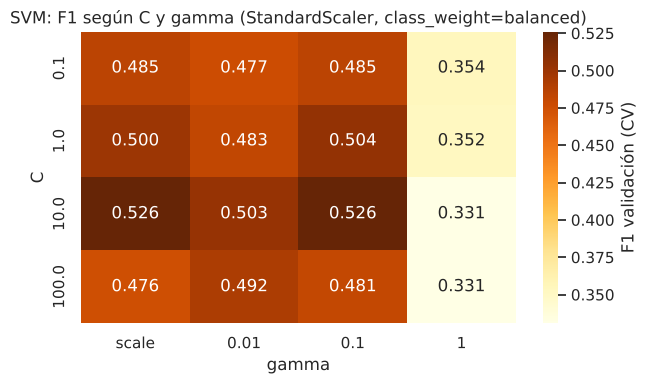

In [25]:
#@title **CÓDIGO:** SVM: búsqueda en rejilla (escalador, C, gamma, pesos de clase)
gs_svm = buscar("SVM (RBF)", Pipeline([("escalado", RobustScaler()), ("svc", SVC(random_state=SEED))]),
                {"escalado": [StandardScaler(), RobustScaler()],
                 "svc__C": [0.1, 1, 10, 100],
                 "svc__gamma": ["scale", 0.01, 0.1, 1],
                 "svc__class_weight": [None, "balanced"]})

res = pd.DataFrame(gs_svm.cv_results_)
mejor_esc = type(gs_svm.best_params_["escalado"]).__name__
mascara = (res["param_escalado"].map(lambda e: type(e).__name__) == mejor_esc) & \
          (res["param_svc__class_weight"].astype(str) == str(gs_svm.best_params_["svc__class_weight"]))
mapa = (res[mascara].assign(gamma=res["param_svc__gamma"].astype(str), C=res["param_svc__C"].astype(float))
        .pivot(index="C", columns="gamma", values="mean_test_score")[["scale", "0.01", "0.1", "1"]])
plt.figure(figsize=(6.5, 4))
sns.heatmap(mapa, annot=True, fmt=".3f", cmap="YlOrBr", cbar_kws={"label": "F1 validación (CV)"})
plt.title(f"SVM: F1 según C y gamma ({mejor_esc}, class_weight={gs_svm.best_params_['svc__class_weight']})")
plt.tight_layout(); plt.show()

Con `gamma = 1` (fronteras muy locales) el F1 de validación cae: es el mismo sobreajuste que se observa con `gamma = 100` en el ejemplo `make_moons` de clase. `StandardScaler` y `RobustScaler` dan resultados muy similares; la búsqueda elige el que obtiene mayor F1 en validación cruzada.

### 14.5 Gradient Boosting

En lugar de árboles independientes (RF), el **boosting** entrena árboles **pequeños en secuencia**: cada árbol nuevo se ajusta a los errores (gradiente de la pérdida) del conjunto anterior, y su aporte se multiplica por `learning_rate`. Hiperparámetros: `n_estimators` (número de etapas), `learning_rate` (tamaño del paso), `max_depth` (tamaño de cada árbol) y `subsample` (fracción de datos por etapa, que añade aleatoriedad).

In [26]:
#@title **CÓDIGO:** Gradient Boosting: búsqueda en rejilla
gs_gb = buscar("Gradient Boosting", GradientBoostingClassifier(random_state=SEED),
               {"n_estimators": [100, 300],
                "learning_rate": [0.05, 0.1],
                "max_depth": [2, 3, 4],
                "subsample": [0.8, 1.0]})

Gradient Boosting: 24 configuraciones × 5 folds = 120 entrenamientos (23.1 s)
  Mejores hiperparámetros: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300, 'subsample': 0.8}
  F1 validación (CV) = 0.497 ± 0.043 | F1 entrenamiento = 0.913


## 15. Comparación de modelos y selección

Las configuraciones elegidas en la sección 14 se comparan con **otra** validación cruzada (5 folds × 3 repeticiones, con una semilla distinta a la usada para ajustar), para reducir el optimismo de reutilizar los mismos folds con que se eligieron los hiperparámetros. Se incluyen las líneas base.

**Criterio de selección (fijado antes de ver los resultados):** mayor **F1 medio** de validación. Si dos modelos quedan a menos de 0,01 de F1, se prefiere el de mayor **PR-AUC**, porque mide la calidad del ordenamiento sin depender del umbral.

In [27]:
#@title **CÓDIGO:** comparación final con CV repetida (5 folds × 3 repeticiones)
candidatos = {"Dummy (siempre 'estándar')": DummyClassifier(strategy="most_frequent"),
              "Regla: alcohol ≥ t": ReglaUmbral("alcohol")}
candidatos.update({nombre: clone(gs.best_estimator_) for nombre, gs in busquedas.items()})

filas_cmp, folds_f1 = [], {}
for nombre, modelo in candidatos.items():
    metr = ("F1", "Recall", "Precision", "Especificidad", "Accuracy") if "Dummy" in nombre else tuple(SCORING)
    fila, sc = resumen_cv(nombre, modelo, X_dev, y_dev, CV_REP, metricas=metr)
    filas_cmp.append(fila)
    folds_f1[nombre] = sc["test_F1"]
comparacion = pd.DataFrame(filas_cmp).set_index("Modelo").reindex(columns=COLS_TABLA)
display(comparacion.round(3).style.highlight_max(subset=["F1", "ROC_AUC", "PR_AUC"], color="#f3dfb0")
        .format("{:.3f}", na_rep="-"))

modelos_ml = [m for m in busquedas]
orden = comparacion.loc[modelos_ml].sort_values(["F1", "PR_AUC"], ascending=False)
mejor, segundo = orden.index[0], orden.index[1]
if orden.loc[mejor, "F1"] - orden.loc[segundo, "F1"] < 0.01 and orden.loc[segundo, "PR_AUC"] > orden.loc[mejor, "PR_AUC"]:
    mejor = segundo
modelo_seleccionado = mejor
print(f"Modelo seleccionado: {modelo_seleccionado} "
      f"(F1 = {comparacion.loc[mejor, 'F1']:.3f} ± {comparacion.loc[mejor, 'F1 (std)']:.3f}, "
      f"PR-AUC = {comparacion.loc[mejor, 'PR_AUC']:.3f})")

,F1,F1 (std),Recall,Precision,Especificidad,Accuracy,ROC_AUC,PR_AUC,F1 train
Modelo,,,,,,,,,
Dummy (siempre 'estándar'),0.000,0.000,0.000,0.000,1.000,0.865,-,-,0.000
Regla: alcohol ≥ t,0.460,0.081,0.510,0.429,0.889,0.837,0.823,0.410,0.481
GNB,0.525,0.062,0.658,0.440,0.866,0.838,0.844,0.478,0.550
Árbol de decisión,0.466,0.034,0.742,0.341,0.774,0.770,0.811,0.444,0.579
Random Forest,0.540,0.051,0.601,0.493,0.903,0.862,0.882,0.609,0.803
SVM (RBF),0.513,0.046,0.637,0.432,0.866,0.835,0.823,0.525,0.772
Gradient Boosting,0.480,0.085,0.420,0.570,0.948,0.876,0.862,0.543,0.911


Modelo seleccionado: Random Forest (F1 = 0.540 ± 0.051, PR-AUC = 0.609)


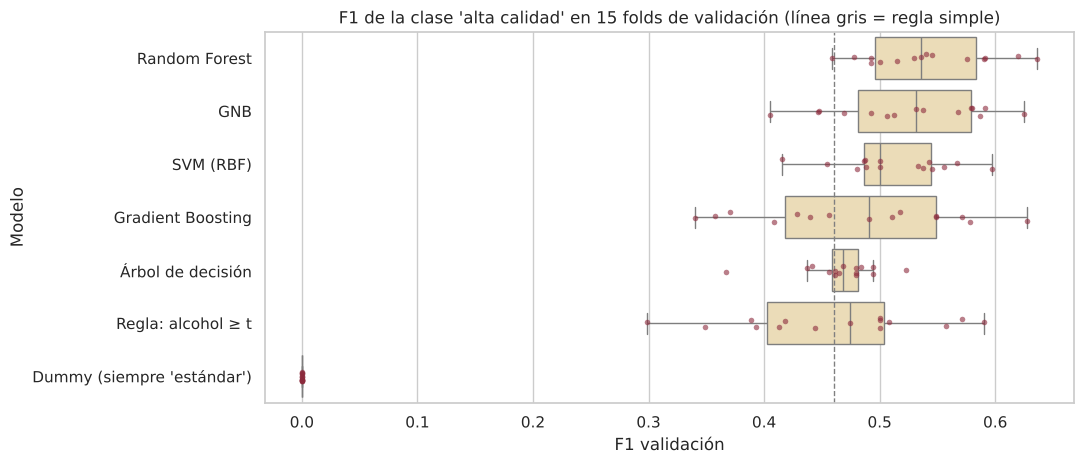

In [28]:
#@title **CÓDIGO:** distribución del F1 en los 15 folds de validación
datos_box = pd.DataFrame(folds_f1).melt(var_name="Modelo", value_name="F1 validación")
orden_box = comparacion.sort_values("F1", ascending=False).index
plt.figure(figsize=(11, 4.8))
sns.boxplot(data=datos_box, y="Modelo", x="F1 validación", order=orden_box, color="#f3dfb0", fliersize=0)
sns.stripplot(data=datos_box, y="Modelo", x="F1 validación", order=orden_box, color=COLOR_STD, size=4, alpha=.6)
plt.axvline(comparacion.loc["Regla: alcohol ≥ t", "F1"], color="gray", ls="--", lw=1)
plt.title("F1 de la clase 'alta calidad' en 15 folds de validación (línea gris = regla simple)")
plt.tight_layout(); plt.show()

**Resultado de la comparación (validación cruzada 5 × 3 en desarrollo):**

- **Random Forest es el seleccionado:** mayor F1 medio (**0,540 ± 0,051**) y, además, el mejor ROC-AUC (**0,882**) y PR-AUC (**0,609**, frente a 0,135 del azar). Supera a GNB por 0,015 de F1, más que el margen de empate fijado (0,01), por lo que no se aplica el desempate.
- **GNB** (0,525) queda segundo pese a su supuesto de independencia violado: es un modelo simple y estable, pero ordena peor los vinos (PR-AUC 0,478).
- **Árbol de decisión** (0,466): alto recall (0,742) pero baja precision (0,341); un solo árbol es inestable y poco preciso.
- **Gradient Boosting** (0,480): la mayor precision (0,570) y especificidad, pero recall bajo (0,420) con el umbral 0,5; además es el más variable entre folds (std 0,085).
- Todos los modelos ajustados superan a la **regla simple** (0,460), aunque el árbol individual solo por 0,006; todos superan al clasificador trivial (F1 = 0).

La brecha entre `F1 train` (0,803) y validación (0,540) del Random Forest indica que aún memoriza parte del entrenamiento, aunque mucho menos que con la configuración por defecto (1,000 vs. 0,419): limitar `max_depth = 8` y `min_samples_leaf = 5` redujo el sobreajuste.

## 16. Ajuste del umbral de decisión

Los clasificadores producen una probabilidad $\hat{p} = P(\text{alta} \mid x)$ y por defecto predicen "alta" si $\hat{p} \geq 0{,}5$. Con clases desbalanceadas ese umbral no tiene por qué ser el óptimo. Para elegirlo **sin tocar el test** se usan predicciones *out-of-fold*: cada vino de desarrollo recibe la probabilidad de un modelo que **no** lo vio al entrenar (`cross_val_predict`). Luego se calcula F1, precision y recall para cada umbral posible.

**Regla de decisión:** solo se cambia el umbral si la mejora de F1 supera la desviación estándar entre folds (≈ 0,05); si no, la "mejora" no se distingue del ruido y se conserva 0,5, que es más simple y menos propenso a sobreajustar.

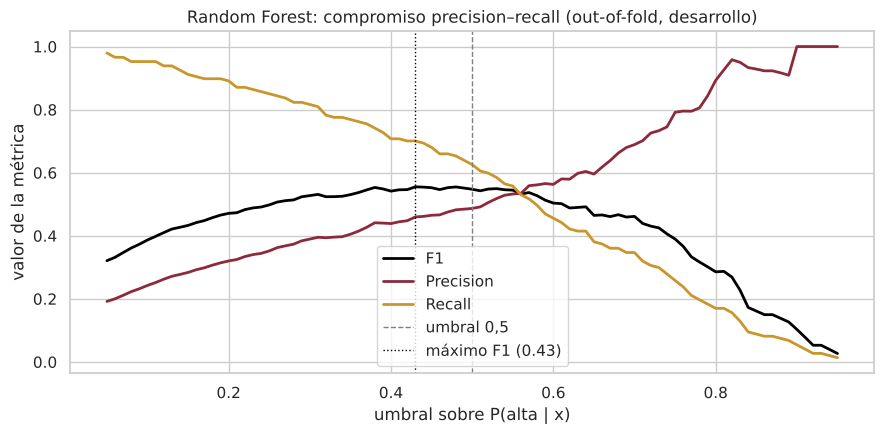

F1 con umbral 0,50: 0.548 | F1 máximo: 0.555 en umbral 0.43 | mejora = +0.008 frente a std entre folds = 0.051
→ Umbral adoptado: 0.50


,F1,Precision,Recall
umbral,,,
0.3,0.527,0.390,0.816
0.4,0.542,0.439,0.707
0.5,0.548,0.487,0.626
0.6,0.504,0.563,0.456
0.7,0.462,0.689,0.347


In [29]:
#@title **CÓDIGO:** F1, precision y recall vs. umbral (predicciones out-of-fold)
modelo_final = clone(busquedas[modelo_seleccionado].best_estimator_)
p_oof = cross_val_predict(modelo_final, X_dev, y_dev, cv=CV5, method="predict_proba")[:, 1]

umbrales = np.round(np.arange(0.05, 0.951, 0.01), 2)
curva_umbral = pd.DataFrame({
    "umbral": umbrales,
    "F1": [f1_score(y_dev, (p_oof >= u).astype(int), zero_division=0) for u in umbrales],
    "Precision": [precision_score(y_dev, (p_oof >= u).astype(int), zero_division=0) for u in umbrales],
    "Recall": [recall_score(y_dev, (p_oof >= u).astype(int), zero_division=0) for u in umbrales]})
u_opt = curva_umbral.loc[curva_umbral["F1"].idxmax(), "umbral"]
f1_05 = curva_umbral.loc[curva_umbral["umbral"] == 0.5, "F1"].iloc[0]
f1_opt = curva_umbral["F1"].max()
std_f1 = comparacion.loc[modelo_seleccionado, "F1 (std)"]
UMBRAL = u_opt if (f1_opt - f1_05) > std_f1 else 0.5

plt.figure(figsize=(9, 4.5))
for col, color in [("F1", "black"), ("Precision", COLOR_STD), ("Recall", COLOR_ALTA)]:
    plt.plot(curva_umbral["umbral"], curva_umbral[col], label=col, color=color, lw=2)
plt.axvline(0.5, color="gray", ls="--", lw=1, label="umbral 0,5")
plt.axvline(u_opt, color="black", ls=":", lw=1, label=f"máximo F1 ({u_opt:.2f})")
plt.xlabel("umbral sobre P(alta | x)"); plt.ylabel("valor de la métrica")
plt.title(f"{modelo_seleccionado}: compromiso precision–recall (out-of-fold, desarrollo)")
plt.legend(); plt.tight_layout(); plt.show()

print(f"F1 con umbral 0,50: {f1_05:.3f} | F1 máximo: {f1_opt:.3f} en umbral {u_opt:.2f} | "
      f"mejora = {f1_opt - f1_05:+.3f} frente a std entre folds = {std_f1:.3f}")
print(f"→ Umbral adoptado: {UMBRAL:.2f}")
display(curva_umbral[curva_umbral["umbral"].isin([0.3, 0.4, 0.5, 0.6, 0.7])].set_index("umbral").round(3))

La tabla de umbrales es útil para el negocio: si la bodega quisiera **no dejar escapar** vinos premium (priorizar recall) podría bajar el umbral, aceptando más falsos positivos que pasarían a una cata de confirmación; si quisiera que todo lo marcado como "alta" lo sea (priorizar precision), lo subiría. El umbral es una **decisión de negocio**, no solo técnica.

## 17. Evaluación final en test

Con el modelo, sus hiperparámetros y el umbral ya fijados, se entrena una vez con **todo el conjunto de desarrollo** (80 %) y se evalúa **por única vez** en el test (20 %, 272 vinos nunca usados). Para contexto se evalúan también las líneas base y los demás modelos ajustados, **sin** usar estos resultados para cambiar la elección.

In [30]:
#@title **CÓDIGO:** entrenamiento final y métricas en test
modelo_final = clone(busquedas[modelo_seleccionado].best_estimator_).fit(X_dev, y_dev)
p_test = modelo_final.predict_proba(X_test)[:, 1]
y_pred_test = (p_test >= UMBRAL).astype(int)

filas_test = []
for nombre, modelo in candidatos.items():
    m = clone(modelo).fit(X_dev, y_dev)
    if nombre == modelo_seleccionado:
        filas_test.append(metricas_pred(f"★ {nombre} (seleccionado)", y_test, y_pred_test, p_test))
    else:
        filas_test.append(metricas_pred(nombre, y_test, m.predict(X_test),
                                        None if "Dummy" in nombre else puntaje(m, X_test)))
tabla_test = pd.DataFrame(filas_test).set_index("Modelo")
display(tabla_test.round(3).style.format("{:.3f}", na_rep="-"))

cv_vs_test = pd.DataFrame({"Validación cruzada (desarrollo)": comparacion.loc[modelo_seleccionado, ["F1", "Recall", "Precision", "Accuracy", "ROC_AUC", "PR_AUC"]],
                           "Test": tabla_test.loc[f"★ {modelo_seleccionado} (seleccionado)", ["F1", "Recall", "Precision", "Accuracy", "ROC_AUC", "PR_AUC"]]})
cv_vs_test["diferencia"] = cv_vs_test["Test"] - cv_vs_test["Validación cruzada (desarrollo)"]
print(f"\n{modelo_seleccionado}: ¿generaliza? (test vs. estimación de la validación cruzada)")
display(cv_vs_test.astype(float).round(3))

,F1,Recall,Precision,Especificidad,Accuracy,ROC_AUC,PR_AUC
Modelo,,,,,,,
Dummy (siempre 'estándar'),0.000,0.000,0.000,1.000,0.864,-,-
Regla: alcohol ≥ t,0.457,0.568,0.382,0.855,0.816,0.832,0.393
GNB,0.489,0.595,0.415,0.868,0.831,0.829,0.490
Árbol de decisión,0.519,0.730,0.403,0.830,0.816,0.814,0.402
★ Random Forest (seleccionado),0.571,0.703,0.481,0.881,0.857,0.877,0.513
SVM (RBF),0.536,0.703,0.433,0.855,0.835,0.870,0.533
Gradient Boosting,0.471,0.432,0.516,0.936,0.868,0.894,0.541



Random Forest: ¿generaliza? (test vs. estimación de la validación cruzada)


,Validación cruzada (desarrollo),Test,diferencia
F1,0.540,0.571,0.031
Recall,0.601,0.703,0.102
Precision,0.493,0.481,-0.012
Accuracy,0.862,0.857,-0.005
ROC_AUC,0.882,0.877,-0.005
PR_AUC,0.609,0.513,-0.096


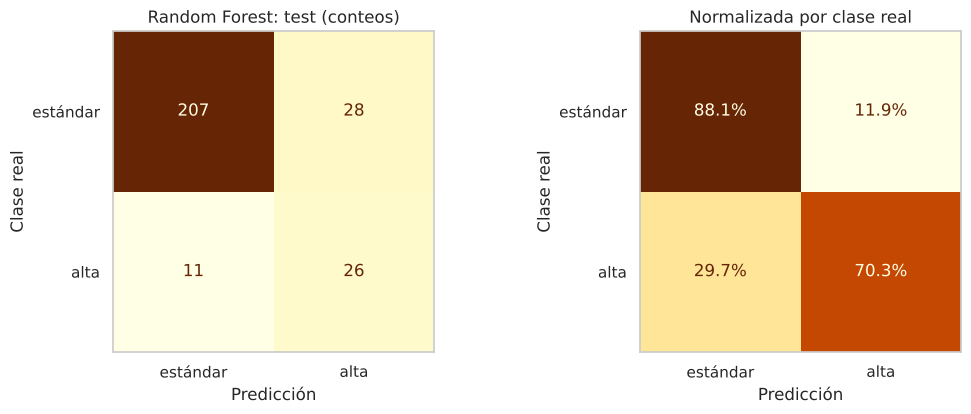

TN = 207 | FP = 28 | FN = 11 | TP = 26
Recall = 26/37 = 0.703 | Precision = 26/54 = 0.481 | Especificidad = 207/235 = 0.881

              precision    recall  f1-score   support

estándar (0)      0.950     0.881     0.914       235
    alta (1)      0.481     0.703     0.571        37

    accuracy                          0.857       272
   macro avg      0.716     0.792     0.743       272
weighted avg      0.886     0.857     0.867       272



In [31]:
#@title **CÓDIGO:** matriz de confusión y reporte de clasificación (test)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, labels=[0, 1], display_labels=["estándar", "alta"],
                                        cmap="YlOrBr", colorbar=False, ax=axes[0])
axes[0].set(title=f"{modelo_seleccionado}: test (conteos)", xlabel="Predicción", ylabel="Clase real")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, labels=[0, 1], display_labels=["estándar", "alta"],
                                        cmap="YlOrBr", colorbar=False, normalize="true", values_format=".1%", ax=axes[1])
axes[1].set(title="Normalizada por clase real", xlabel="Predicción", ylabel="Clase real")
for ax in axes:
    ax.grid(False)
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test, labels=[0, 1]).ravel()
print(f"TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}")
print(f"Recall = {tp}/{tp + fn} = {tp / (tp + fn):.3f} | Precision = {tp}/{tp + fp} = {tp / (tp + fp):.3f} | "
      f"Especificidad = {tn}/{tn + fp} = {tn / (tn + fp):.3f}\n")
print(classification_report(y_test, y_pred_test, target_names=["estándar (0)", "alta (1)"], digits=3))

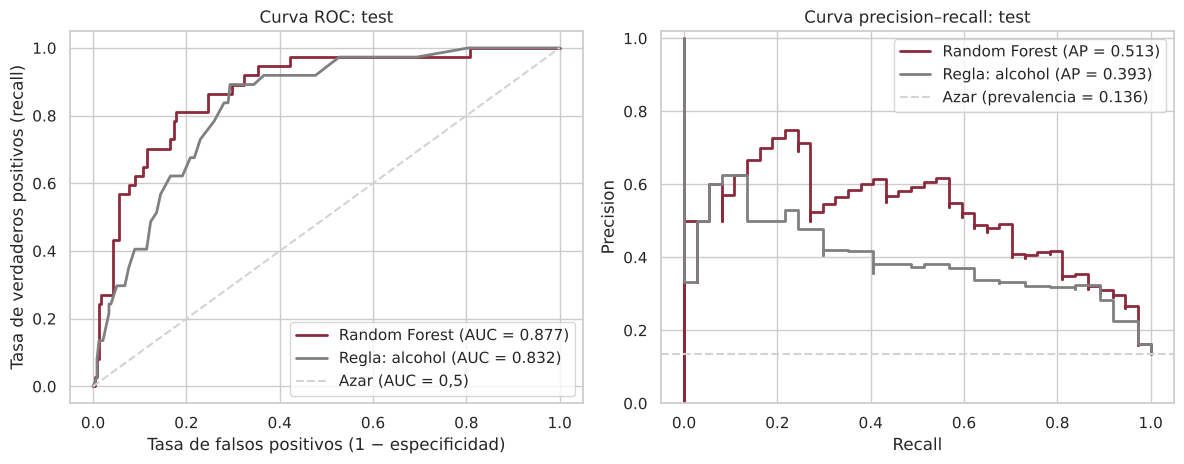

In [32]:
#@title **CÓDIGO:** curvas ROC y precision–recall (test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
regla_fit = ReglaUmbral("alcohol").fit(X_dev, y_dev)
for nombre, s, color in [(modelo_seleccionado, p_test, COLOR_STD),
                         ("Regla: alcohol", regla_fit.decision_function(X_test), "gray")]:
    fpr, tpr, _ = roc_curve(y_test, s)
    prec, rec, _ = precision_recall_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{nombre} (AUC = {roc_auc_score(y_test, s):.3f})")
    axes[1].step(rec, prec, where="post", color=color, lw=2, label=f"{nombre} (AP = {average_precision_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="lightgray", label="Azar (AUC = 0,5)")
axes[0].set(title="Curva ROC: test", xlabel="Tasa de falsos positivos (1 − especificidad)", ylabel="Tasa de verdaderos positivos (recall)")
axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), ls="--", color="lightgray", label=f"Azar (prevalencia = {y_test.mean():.3f})")
axes[1].set(title="Curva precision–recall: test", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

In [33]:
#@title **CÓDIGO:** análisis de errores: ¿qué quality real tienen los vinos mal clasificados?
errores = df_nodup.loc[X_test.index, ["quality", "alcohol", "volatile_acidity", "sulphates"]].copy()
errores["real"], errores["predicho"], errores["P(alta)"] = y_test.values, y_pred_test, p_test
errores["tipo"] = np.select([(errores.real == 1) & (errores.predicho == 1), (errores.real == 0) & (errores.predicho == 0),
                             (errores.real == 0) & (errores.predicho == 1)], ["TP", "TN", "FP"], default="FN")
display(pd.crosstab(errores["tipo"], errores["quality"]).reindex(["TP", "FN", "FP", "TN"]))
fp_q6 = ((errores.tipo == "FP") & (errores.quality == 6)).sum()
print(f"De los {fp} falsos positivos, {fp_q6} tienen quality = 6 ({fp_q6 / fp:.0%}): están justo debajo del umbral de negocio.")
display(errores.groupby("tipo")[["alcohol", "volatile_acidity", "sulphates", "P(alta)"]].median().reindex(["TP", "FN", "FP", "TN"]).round(3))

quality,3,4,5,6,7,8
tipo,,,,,,
TP,0,0,0,0,22,4
FN,0,0,0,0,11,0
FP,0,0,0,28,0,0
TN,3,11,118,75,0,0


De los 28 falsos positivos, 28 tienen quality = 6 (100%): están justo debajo del umbral de negocio.


,alcohol,volatile_acidity,sulphates,P(alta)
tipo,,,,
TP,11.8,0.35,0.765,0.708
FN,10.9,0.55,0.620,0.259
FP,11.9,0.32,0.720,0.622
TN,9.9,0.58,0.580,0.065


**Lectura de la evaluación final (test, 272 vinos nunca vistos):**

- **F1 = 0,571**, recall = 0,703 y precision = 0,481: el modelo detecta **26 de los 37** vinos de alta calidad y, de los 54 vinos que marca como "alta", 26 lo son. La especificidad es 0,881 (207 de 235 vinos estándar bien reconocidos) y ROC-AUC = 0,877.
- **Supera a las líneas base en test:** F1 0,571 frente a 0,457 de la regla `alcohol ≥ 11,6` y 0 del clasificador trivial; la accuracy (0,857) es incluso algo menor que la del trivial (0,864), lo que confirma que la accuracy no era la métrica adecuada.
- **Generaliza:** el F1 de test (0,571) está dentro del rango esperado por la validación cruzada (0,540 ± 0,051); ROC-AUC y accuracy prácticamente coinciden. El PR-AUC de test (0,513) es menor que el de validación (0,609), lo esperable con solo 37 positivos en test.
- **Los errores son "de frontera":** los **28 falsos positivos tienen `quality = 6`** (ningún vino de calidad 3–5 fue confundido con uno de alta calidad) y los **11 falsos negativos tienen `quality = 7`** (el modelo detectó los 4 vinos de calidad 8). El modelo se equivoca justo alrededor del umbral de negocio 6/7, donde incluso los catadores pueden discrepar. Los falsos negativos tienen menos alcohol y más acidez volátil que los verdaderos positivos: son vinos de calidad 7 con perfil químico "de vino estándar".

## 18. Interpretación: ¿qué propiedades influyen en la calidad?

Este es el segundo objetivo del proyecto. Se usan dos medidas complementarias:

- **Importancia por impureza (MDI):** cuánto reduce cada variable la impureza Gini, promediado en todos los árboles. Es rápida pero se calcula con datos de entrenamiento y puede favorecer variables con muchos valores distintos.
- **Importancia por permutación (en test):** cuánto **cae el F1** en test cuando se desordenan aleatoriamente los valores de una variable (rompiendo su relación con la calidad). Se calcula con datos no vistos y se repite 30 veces.

Ninguna de las dos demuestra **causalidad**: indican en qué se apoya el modelo para predecir.

,Importancia MDI,Caída de F1 al permutar (test),std permutación,ρ Spearman con quality (EDA),Ranking permutación
alcohol,0.253,0.210,0.052,0.479,1
sulphates,0.166,0.149,0.070,0.377,2
volatile_acidity,0.125,0.063,0.029,-0.381,3
citric_acid,0.103,0.054,0.044,0.213,4
density,0.076,0.033,0.034,-0.177,5
chlorides,0.055,0.031,0.019,-0.190,6
residual_sugar,0.029,0.017,0.011,0.032,7
total_sulfur_dioxide,0.066,0.017,0.022,-0.197,8
fixed_acidity,0.057,0.007,0.016,0.114,9
pH,0.037,0.006,0.014,-0.044,10


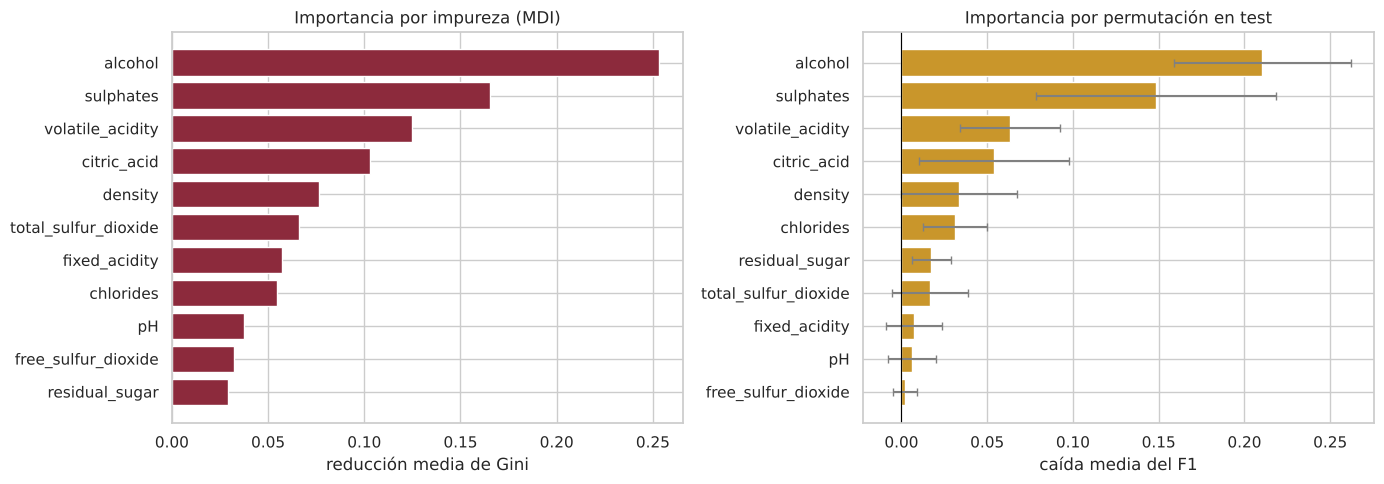

In [34]:
#@title **CÓDIGO:** importancia de variables (impureza y permutación)
imp_mdi = pd.Series(getattr(modelo_final, "feature_importances_", np.full(len(VARIABLES), np.nan)), index=VARIABLES)
perm = permutation_importance(modelo_final, X_test, y_test, scoring=SCORING["F1"], n_repeats=30,
                              random_state=SEED, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=VARIABLES)
imp_perm_std = pd.Series(perm.importances_std, index=VARIABLES)

tabla_imp = pd.DataFrame({"Importancia MDI": imp_mdi, "Caída de F1 al permutar (test)": imp_perm,
                          "std permutación": imp_perm_std, "ρ Spearman con quality (EDA)": spearman_q}).sort_values(
                          "Caída de F1 al permutar (test)", ascending=False)
tabla_imp["Ranking permutación"] = np.arange(1, len(VARIABLES) + 1)
display(tabla_imp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
o = imp_mdi.sort_values()
axes[0].barh(o.index, o.values, color=COLOR_STD)
axes[0].set(title="Importancia por impureza (MDI)", xlabel="reducción media de Gini")
o = imp_perm.sort_values()
axes[1].barh(o.index, o.values, xerr=imp_perm_std[o.index], color=COLOR_ALTA, ecolor="gray", capsize=3)
axes[1].axvline(0, color="black", lw=.8)
axes[1].set(title="Importancia por permutación en test", xlabel="caída media del F1")
plt.tight_layout(); plt.show()

**Las cuatro variables más importantes son `alcohol`, `sulphates`, `volatile_acidity` y `citric_acid`** con ambas medidas, exactamente las candidatas que identificó el EDA de la Entrega 1 (sección 7). Permutar `alcohol` reduce el F1 de test en ≈ 0,21 y `sulphates` en ≈ 0,15; las variables de sulfitos libres, pH y acidez fija aportan muy poco (caída < 0,01) una vez el modelo conoce las demás, en parte porque comparten información con ellas (multicolinealidad).

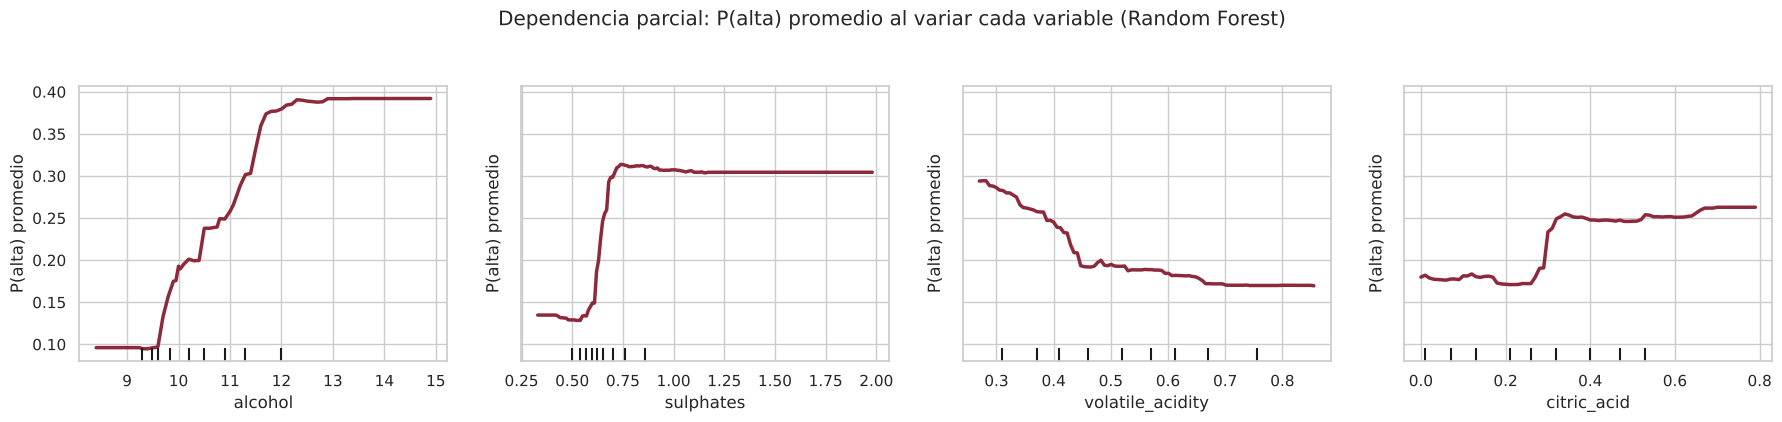

In [35]:
#@title **CÓDIGO:** dirección del efecto: dependencia parcial de las 4 variables más importantes
from sklearn.inspection import PartialDependenceDisplay
top4 = list(imp_perm.sort_values(ascending=False).index[:4])
fig, ax = plt.subplots(figsize=(18, 4))
pdp = PartialDependenceDisplay.from_estimator(modelo_final, X_dev, top4, kind="average", ax=ax, n_cols=4,
                                              line_kw={"color": COLOR_STD, "lw": 2.5})
for a in np.ravel(pdp.axes_):
    if a is not None:
        a.set_ylabel("P(alta) promedio")
fig.suptitle(f"Dependencia parcial: P(alta) promedio al variar cada variable ({modelo_seleccionado})", y=1.05)
plt.tight_layout(); plt.show()

La dependencia parcial muestra **en qué dirección** se mueve la probabilidad estimada de "alta calidad" cuando una variable cambia y las demás se mantienen como en los datos. Estas relaciones describen el comportamiento del modelo y son coherentes con el EDA (Spearman), pero no son experimentos: no prueban que modificar una variable cause un cambio en la calidad.

- **`alcohol`:** la probabilidad sube de ≈ 0,10 (menos de 9,5 %) a ≈ 0,39 (más de 12 %); es el efecto más fuerte.
- **`sulphates`:** salto marcado entre ≈ 0,60 y 0,75 g/L; por encima de ese rango ya no aumenta.
- **`volatile_acidity`:** efecto **negativo**: más acidez volátil (asociada a sabor avinagrado) → menor probabilidad de alta calidad.
- **`citric_acid`:** aumento moderado a partir de ≈ 0,3 g/L.

## 19. Curva de aprendizaje

¿Mejoraría el modelo con más datos? La curva de aprendizaje entrena el modelo con fracciones crecientes del conjunto de desarrollo (siempre con CV estratificada) y compara el F1 de entrenamiento y de validación.

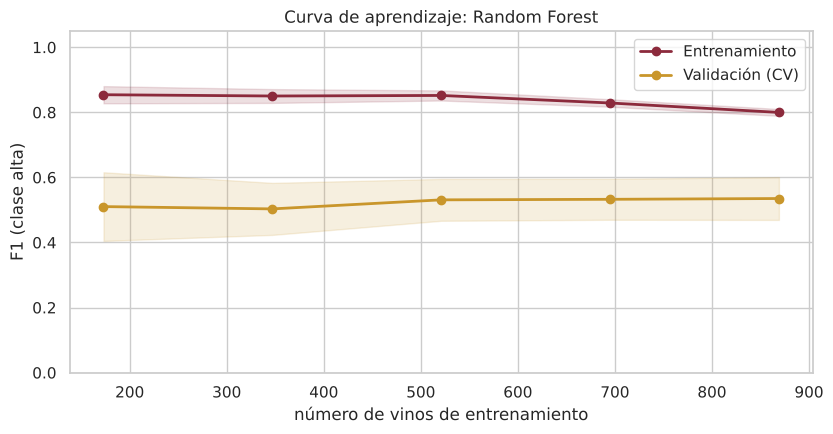

,vinos de entrenamiento,F1 train,F1 validación,brecha
0,173,0.854,0.510,0.344
1,347,0.850,0.503,0.347
2,521,0.852,0.531,0.321
3,695,0.829,0.533,0.296
4,869,0.800,0.535,0.265


In [36]:
#@title **CÓDIGO:** curva de aprendizaje del modelo seleccionado
tam, tr_lc, va_lc = learning_curve(clone(modelo_final), X_dev, y_dev, cv=CV5, scoring=SCORING["F1"],
                                   train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1, shuffle=True, random_state=SEED)
plt.figure(figsize=(8.5, 4.5))
for datos, nombre, color in [(tr_lc, "Entrenamiento", COLOR_STD), (va_lc, "Validación (CV)", COLOR_ALTA)]:
    plt.plot(tam, datos.mean(axis=1), "o-", color=color, lw=2, label=nombre)
    plt.fill_between(tam, datos.mean(axis=1) - datos.std(axis=1), datos.mean(axis=1) + datos.std(axis=1), color=color, alpha=.15)
plt.xlabel("número de vinos de entrenamiento"); plt.ylabel("F1 (clase alta)"); plt.ylim(0, 1.05)
plt.title(f"Curva de aprendizaje: {modelo_seleccionado}"); plt.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame({"vinos de entrenamiento": tam, "F1 train": tr_lc.mean(axis=1),
                      "F1 validación": va_lc.mean(axis=1), "brecha": tr_lc.mean(axis=1) - va_lc.mean(axis=1)}).round(3))

Al pasar de 173 a 869 vinos de entrenamiento, el F1 de validación sube de ≈ 0,51 a ≈ 0,54 y la brecha con entrenamiento se reduce de 0,34 a 0,27. Las curvas aún no se juntan: **más datos ayudarían, pero con rendimientos decrecientes**. La principal limitación no es el modelo sino la información disponible: con 147 vinos de alta calidad en desarrollo y clases que se solapan químicamente (sección 8), el techo de F1 es moderado.

## 20. Conclusiones de la Parte 2

1. El modelo seleccionado es un Random Forest (300 árboles, `max_depth = 8`, `min_samples_leaf = 5`, `max_features = "sqrt"`, `class_weight = "balanced_subsample"`, umbral 0,5). En validación cruzada obtuvo F1 = 0,540 ± 0,051 y en el test final F1 = 0,571, con recall = 0,703, precision = 0,481 y ROC-AUC = 0,877.
2. Supera a la regla manual `alcohol ≥ 11,6` (F1 en test 0,457) y al clasificador trivial (F1 = 0 con 86 % de accuracy), así que cumple el primer objetivo del proyecto.
3. Las propiedades más influyentes son `alcohol` (+), `sulphates` (+), `volatile_acidity` (−) y `citric_acid` (+). Coinciden en el EDA (Spearman), en la importancia por impureza y en la importancia por permutación en test.
4. Todos los falsos positivos son vinos de calidad 6 y todos los falsos negativos son de calidad 7: el modelo no confunde vinos claramente malos con vinos premium.
5. Las decisiones de método que más pesaron fueron quitar los duplicados antes de partir, dejar el test intocado hasta el final, decidir con validación cruzada en lugar de una sola partición (que llegó a sobreestimar a GNB en cerca de 0,15), manejar el desbalance con pesos de clase y usar F1 como métrica principal.

La Parte 3 plantea el mismo problema como regresión, para ver si predecir el puntaje de calidad funciona mejor que clasificar.

---
# **PARTE 3. REGRESIÓN: PREDECIR EL PUNTAJE DE CALIDAD (Entrega final)**

## 21. Planteamiento del problema de regresión

En las Partes 1 y 2 la pregunta fue "¿este vino es de alta calidad?", con dos respuestas posibles. Pero `quality` es un puntaje numérico que los catadores asignaron de 0 a 10 (en estos datos va de 3 a 8). La regresión intenta predecir ese número directamente.

La diferencia con la clasificación está en lo que devuelve el modelo:

- En clasificación el modelo estima una probabilidad, $P(y \mid x)$, y con un umbral la convierte en una clase.
- En regresión el modelo estima un valor, $\hat{y}$ (se lee "y gorro"), que puede ser cualquier número: 5,4 o 6,8, por ejemplo.

Por eso las métricas de la Parte 2 no sirven aquí. Precision, recall y F1 cuentan aciertos y errores, y en regresión casi nunca hay un acierto exacto: si el vino tiene 6 y el modelo dice 5,9, no tiene sentido decir que "falló". Lo que se mide es qué tan lejos queda $\hat{y}$ del valor real.

Para poder comparar con la clasificación se usan los mismos vinos: el mismo conjunto de desarrollo (1.087 vinos) y el mismo test (272 vinos), que sigue sin usarse hasta el final.

,desarrollo,test,% desarrollo
quality,,,
3,7,3,0.6
4,42,11,3.9
5,459,118,42.2
6,432,103,39.7
7,134,33,12.3
8,13,4,1.2


Desarrollo: media = 5.63, desviación estándar = 0.82
Test:       media = 5.60, desviación estándar = 0.85


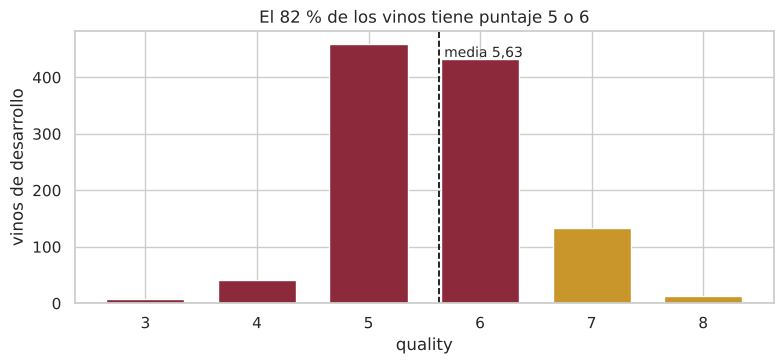

In [37]:
#@title **CÓDIGO:** el puntaje `quality` en desarrollo y test
q = df_nodup["quality"]
q_dev = q.loc[X_dev.index]
q_test = q.loc[X_test.index]

dist_q = pd.DataFrame({"desarrollo": q_dev.value_counts().sort_index(),
                       "test": q_test.value_counts().sort_index()}).fillna(0).astype(int)
dist_q["% desarrollo"] = dist_q["desarrollo"] / dist_q["desarrollo"].sum() * 100
display(dist_q.round(1))
print(f"Desarrollo: media = {q_dev.mean():.2f}, desviación estándar = {q_dev.std(ddof=0):.2f}")
print(f"Test:       media = {q_test.mean():.2f}, desviación estándar = {q_test.std(ddof=0):.2f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
colores = [COLOR_ALTA if v >= 7 else COLOR_STD for v in dist_q.index]
ax.bar(dist_q.index, dist_q["desarrollo"], color=colores, width=0.7)
ax.axvline(q_dev.mean(), color="black", ls="--", lw=1.2)
ax.text(q_dev.mean() + 0.05, dist_q["desarrollo"].max() * 0.95, f"media {q_dev.mean():.2f}".replace(".", ","), fontsize=10)
ax.set_xlabel("quality"); ax.set_ylabel("vinos de desarrollo")
ax.set_title("El 82 % de los vinos tiene puntaje 5 o 6")
plt.tight_layout(); plt.show()

El puntaje está muy concentrado: casi todos los vinos tienen 5 o 6 y muy pocos tienen 3 u 8. Esto va a pesar en los resultados, porque un modelo de regresión aprende mucho de los puntajes frecuentes y poco de los extremos, que son justo los vinos más buenos y los más malos.

## 22. Métricas de regresión

Hay muchas métricas para medir la distancia entre $y$ (el valor real) y $\hat{y}$ (la predicción). Se usan cuatro, las mismas de las notas de clase, y una quinta en porcentaje:

$$MSE = \frac{1}{N}\sum_{i=1}^{N} (y_i - \hat{y}_i)^2 \qquad RMSE = \sqrt{MSE} \qquad MAE = \frac{1}{N}\sum_{i=1}^{N} |y_i - \hat{y}_i|$$

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2} \qquad MAPE = \frac{100}{N}\sum_{i=1}^{N} \left|\frac{y_i - \hat{y}_i}{y_i}\right|$$

| Métrica | Qué mide | Cómo se lee |
|---|---|---|
| MSE (error cuadrático medio) | Promedio de los errores al cuadrado | Menor es mejor. Al elevar al cuadrado, un solo error grande pesa mucho. Es fácil de derivar, por eso muchos modelos lo minimizan al entrenar. |
| RMSE (raíz del MSE) | Lo mismo, devuelto a las unidades de `quality` | Menor es mejor. "El modelo se equivoca en unos 0,6 puntos". |
| MAE (error absoluto medio) | Promedio de los errores sin signo | Menor es mejor. Todos los errores pesan igual, así que es menos sensible a casos raros. |
| R² (coeficiente de determinación) | Qué parte de la variación de `quality` explica el modelo | 1 es perfecto. 0 es lo mismo que predecir siempre la media. Puede ser negativo si el modelo es peor que la media. |
| MAPE (error porcentual medio) | Error relativo al valor real | "El modelo se equivoca en un 9 % del puntaje". |

Para entender bien el MSE, como se propone en clase, se implementa a mano y se compara con la función de scikit-learn.

In [38]:
#@title **CÓDIGO:** MSE implementado a mano y efecto de un error grande
def mse_propio(y_real, y_pred):
    """Error cuadrático medio: promedio de (real - predicho)²."""
    y_real, y_pred = np.asarray(y_real, dtype=float), np.asarray(y_pred, dtype=float)
    return np.mean((y_real - y_pred) ** 2)

def metricas_reg(y_real, y_pred):
    """Las cinco métricas de regresión para un conjunto de predicciones."""
    mse = mean_squared_error(y_real, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_real, y_pred),
            "R²": r2_score(y_real, y_pred),
            "MAPE (%)": np.mean(np.abs((np.asarray(y_real) - np.asarray(y_pred)) / np.asarray(y_real))) * 100}

ejemplo_real = np.array([5, 6, 7, 6])
ejemplo_pred = np.array([5.4, 6.1, 6.3, 6.0])
print(f"MSE propio = {mse_propio(ejemplo_real, ejemplo_pred):.4f} | MSE de scikit-learn = {mean_squared_error(ejemplo_real, ejemplo_pred):.4f}")

# Mismo ejemplo, pero un vino de puntaje 8 que el modelo predice como 5 (un error de 3 puntos)
ejemplo_real_2 = np.append(ejemplo_real, 8)
ejemplo_pred_2 = np.append(ejemplo_pred, 5.0)
comparacion_metricas = pd.DataFrame({"4 vinos con errores pequeños": metricas_reg(ejemplo_real, ejemplo_pred),
                                     "+ 1 vino con error de 3 puntos": metricas_reg(ejemplo_real_2, ejemplo_pred_2)}).T
display(comparacion_metricas.round(3))

MSE propio = 0.1650 | MSE de scikit-learn = 0.1650


,MSE,RMSE,MAE,R²,MAPE (%)
4 vinos con errores pequeños,0.165,0.406,0.30,0.670,4.917
+ 1 vino con error de 3 puntos,1.932,1.390,0.84,-0.858,11.433


La implementación propia da lo mismo que scikit-learn. El segundo ejemplo muestra la diferencia entre MSE y MAE: un solo vino con error de 3 puntos multiplica el MSE por más de 10, mientras que el MAE solo se multiplica por 3. Por eso el RMSE (que viene del MSE) castiga más los errores grandes que el MAE.

Como métrica principal se usa el RMSE, porque está en las mismas unidades que `quality` y castiga los errores grandes, que en este problema son los costosos: decir que un vino de 8 es de 5. El MAE y el R² se reportan siempre como apoyo.

## 23. Intuición con una sola variable: árbol de regresión con `alcohol`

En clase se usó la temperatura para predecir la demanda de bicicletas. Aquí se hace lo mismo con la variable más relacionada con la calidad, `alcohol`, para ver cómo "piensa" un árbol de regresión antes de usar las 11 variables.

Un árbol de regresión hace las mismas preguntas de sí o no que el de clasificación. La diferencia está en la hoja: en vez de votar por una clase, predice el **promedio de `quality`** de los vinos que llegaron a esa hoja. Por eso su predicción tiene forma de escalera. Se comparan dos árboles: uno de profundidad 2 y otro de profundidad 10.

alcohol = 9.5 % vol. → profundidad 2 predice 5.24 | profundidad 10 predice 5.36
alcohol = 12.5 % vol. → profundidad 2 predice 6.39 | profundidad 10 predice 6.57
Hojas: profundidad 2 = 4 | profundidad 10 = 60


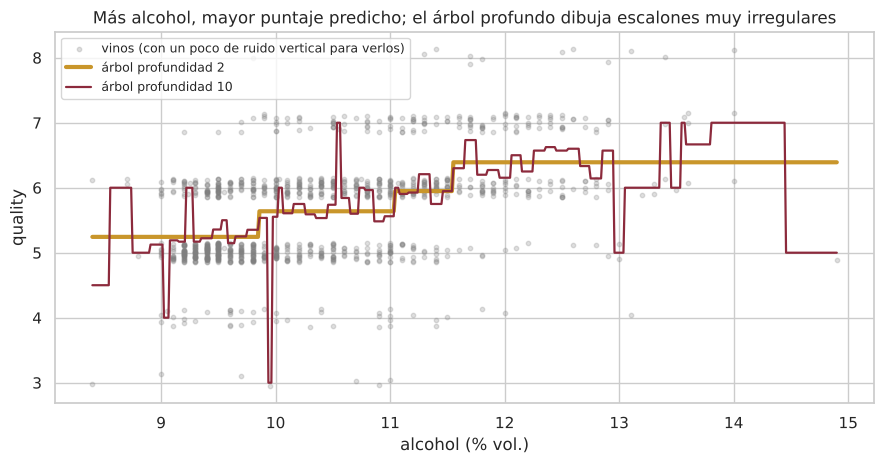

In [39]:
#@title **CÓDIGO:** árboles de regresión con una sola variable (profundidad 2 y 10)
X_alc = X_dev[["alcohol"]]
arbol_2 = DecisionTreeRegressor(max_depth=2, random_state=SEED).fit(X_alc, q_dev)
arbol_10 = DecisionTreeRegressor(max_depth=10, random_state=SEED).fit(X_alc, q_dev)

for alc in [9.5, 12.5]:
    ej = pd.DataFrame({"alcohol": [alc]})
    print(f"alcohol = {alc} % vol. → profundidad 2 predice {arbol_2.predict(ej)[0]:.2f} | "
          f"profundidad 10 predice {arbol_10.predict(ej)[0]:.2f}")
print(f"Hojas: profundidad 2 = {arbol_2.get_n_leaves()} | profundidad 10 = {arbol_10.get_n_leaves()}")

rejilla_alc = pd.DataFrame({"alcohol": np.linspace(X_alc["alcohol"].min(), X_alc["alcohol"].max(), 500)})
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.scatter(X_alc["alcohol"], q_dev + rng.uniform(-0.15, 0.15, len(q_dev)), s=10, alpha=.25, color="gray", label="vinos (con un poco de ruido vertical para verlos)")
ax.plot(rejilla_alc["alcohol"], arbol_2.predict(rejilla_alc), color=COLOR_ALTA, lw=3, label="árbol profundidad 2")
ax.plot(rejilla_alc["alcohol"], arbol_10.predict(rejilla_alc), color=COLOR_STD, lw=1.6, label="árbol profundidad 10")
ax.set_xlabel("alcohol (% vol.)"); ax.set_ylabel("quality")
ax.set_title("Más alcohol, mayor puntaje predicho; el árbol profundo dibuja escalones muy irregulares")
ax.legend(loc="upper left", fontsize=9); plt.tight_layout(); plt.show()

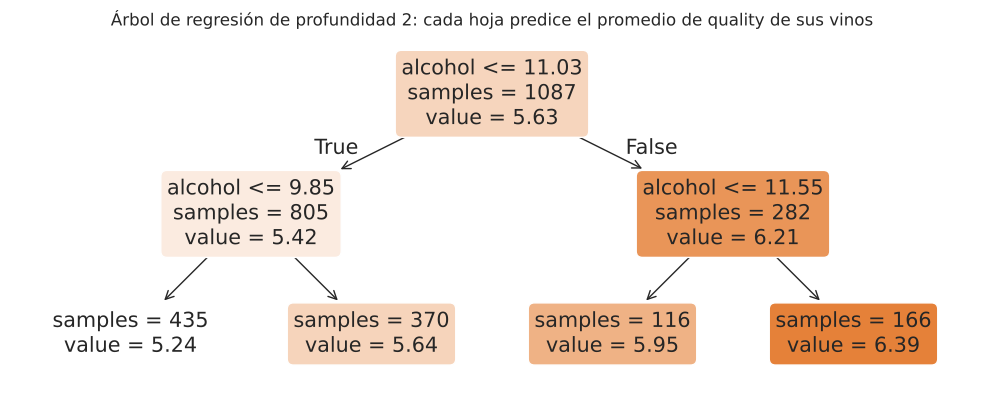

,MSE entrenamiento,MSE validación,MSE validación (std)
Árbol,,,
profundidad 2,0.508,0.518,0.082
profundidad 10,0.468,0.542,0.080


In [40]:
#@title **CÓDIGO:** reglas del árbol de profundidad 2 y error con validación cruzada (KFold de 10)
fig, ax = plt.subplots(figsize=(10, 4.2))
plot_tree(arbol_2, feature_names=["alcohol"], filled=True, rounded=True, impurity=False, precision=2, ax=ax)
ax.set_title("Árbol de regresión de profundidad 2: cada hoja predice el promedio de quality de sus vinos")
plt.tight_layout(); plt.show()

KF10 = KFold(n_splits=10, shuffle=True, random_state=SEED)
filas_alc = []
for nombre, arbol in [("profundidad 2", arbol_2), ("profundidad 10", arbol_10)]:
    s = cross_validate(clone(arbol), X_alc, q_dev, cv=KF10, scoring="neg_mean_squared_error", return_train_score=True)
    filas_alc.append({"Árbol": nombre, "MSE entrenamiento": -s["train_score"].mean(),
                      "MSE validación": -s["test_score"].mean(), "MSE validación (std)": s["test_score"].std()})
display(pd.DataFrame(filas_alc).set_index("Árbol").round(3))

El árbol de profundidad 2 usa tres cortes de alcohol y produce cuatro escalones: a más alcohol, mayor puntaje predicho. El de profundidad 10 tiene muchísimas hojas y su predicción salta de un valor a otro con cambios mínimos de alcohol: se está acomodando a vinos concretos. En validación cruzada (10 folds, como en clase), el árbol profundo tiene menor error en entrenamiento pero **mayor** error en validación. Es el mismo sobreajuste de la Parte 2, ahora medido con MSE.

Con una sola variable el error de validación queda en un MSE de 0,52 (RMSE ≈ 0,72). Las secciones siguientes usan las 11 variables para bajarlo.

## 24. Protocolo de validación y líneas base

Se sigue el mismo protocolo de la Parte 2, con dos ajustes propios de la regresión:

1. La validación cruzada usa `KFold` (5 folds, mezclando los vinos) en vez de `StratifiedKFold`. Estratificar sirve cuando la respuesta es una clase; aquí la respuesta es un número y `KFold` es lo que se usa en las notas de clase.
2. La comparación final usa `RepeatedKFold` (5 folds × 3 repeticiones) con otra semilla, igual que en la Parte 2.

Antes de ajustar modelos se revisan dos cosas que se vieron en clase: cuánto cambia el resultado con una sola partición 80/20 y qué pasa al cambiar el número de folds $K$.

In [41]:
#@title **CÓDIGO:** esquemas de validación y funciones de apoyo para regresión
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import LinearRegression

KF5 = KFold(n_splits=5, shuffle=True, random_state=SEED)
KF_REP = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED + 1)
SCORING_REG = {"MSE": "neg_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

def resumen_reg(nombre, modelo, cv, X_=None, y_=None):
    """Validación cruzada de un regresor: media (y desviación) de RMSE, MAE y R², más el RMSE de entrenamiento."""
    X_ = X_dev if X_ is None else X_
    y_ = q_dev if y_ is None else y_
    s = cross_validate(modelo, X_, y_, cv=cv, scoring=SCORING_REG, return_train_score=True, n_jobs=-1)
    rmse = np.sqrt(-s["test_MSE"])
    return {"Modelo": nombre, "RMSE": rmse.mean(), "RMSE (std)": rmse.std(), "MAE": -s["test_MAE"].mean(),
            "R²": s["test_R2"].mean(), "RMSE train": np.sqrt(-s["train_MSE"]).mean()}

print("KF5 =", KF5, "\nKF_REP =", KF_REP)

KF5 = KFold(n_splits=5, random_state=21, shuffle=True) 
KF_REP = RepeatedKFold(n_repeats=3, n_splits=5, random_state=22)


In [42]:
#@title **CÓDIGO:** ¿qué tan estable es una sola partición 80/20? (30 particiones distintas del desarrollo)
filas_split = []
for semilla in range(30):
    Xa, Xb, qa, qb = train_test_split(X_dev, q_dev, test_size=0.20, random_state=semilla)
    for nombre, reg in [("Regresión lineal", Pipeline([("escalado", StandardScaler()), ("lineal", LinearRegression())])),
                        ("Random Forest (por defecto)", RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1))]:
        pred = clone(reg).fit(Xa, qa).predict(Xb)
        filas_split.append({"semilla": semilla, "Modelo": nombre, "RMSE": np.sqrt(mean_squared_error(qb, pred))})
var_split_reg = pd.DataFrame(filas_split)
display(var_split_reg.groupby("Modelo")["RMSE"].agg(["min", "mean", "max", "std"]).round(3))

ganador_por_split = var_split_reg.pivot(index="semilla", columns="Modelo", values="RMSE").idxmin(axis=1).value_counts()
print("Modelo con menor RMSE en cada una de las 30 particiones:", ganador_por_split.to_dict())

,min,mean,max,std
Modelo,,,,
Random Forest (por defecto),0.605,0.647,0.704,0.021
Regresión lineal,0.615,0.667,0.699,0.024


Modelo con menor RMSE en cada una de las 30 particiones: {'Random Forest (por defecto)': 26, 'Regresión lineal': 4}


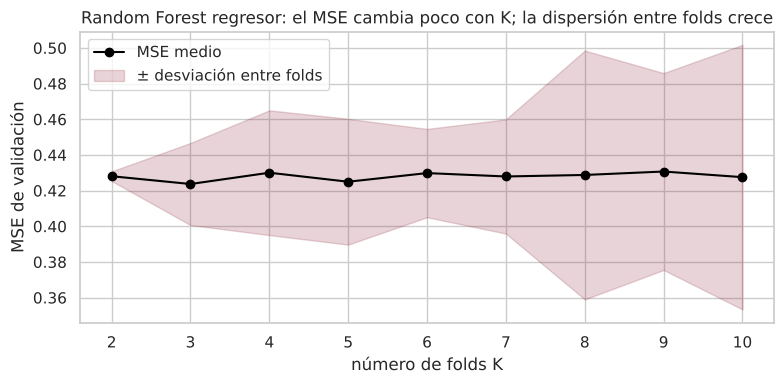

,K,MSE medio,MSE std,vinos de entrenamiento por fold
0,2,0.428,0.003,543
1,3,0.424,0.023,724
2,4,0.430,0.035,815
3,5,0.425,0.035,869
4,6,0.430,0.025,905
5,7,0.428,0.032,931
6,8,0.429,0.070,951
7,9,0.431,0.055,966
8,10,0.428,0.074,978


In [43]:
#@title **CÓDIGO:** efecto del número de folds K en la validación cruzada (como en las notas de clase)
filas_k = []
for k in range(2, 11):
    s = cross_validate(RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1), X_dev, q_dev,
                       cv=KFold(n_splits=k, shuffle=True, random_state=SEED), scoring="neg_mean_squared_error")
    filas_k.append({"K": k, "MSE medio": -s["test_score"].mean(), "MSE std": s["test_score"].std(),
                    "vinos de entrenamiento por fold": int(len(X_dev) * (k - 1) / k)})
curva_k = pd.DataFrame(filas_k)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curva_k["K"], curva_k["MSE medio"], "o-", color="black", label="MSE medio")
ax.fill_between(curva_k["K"], curva_k["MSE medio"] - curva_k["MSE std"], curva_k["MSE medio"] + curva_k["MSE std"],
                color=COLOR_STD, alpha=.2, label="± desviación entre folds")
ax.set_xlabel("número de folds K"); ax.set_ylabel("MSE de validación")
ax.set_title("Random Forest regresor: el MSE cambia poco con K; la dispersión entre folds crece")
ax.legend(); plt.tight_layout(); plt.show()
display(curva_k.round(3))

Las dos pruebas llevan a la misma decisión que en la Parte 2:

- Con una sola partición 80/20 el RMSE de un mismo modelo cambia bastante según qué vinos caigan en validación, y en varias particiones el modelo "ganador" cambia. Decidir con una sola partición sería decidir con suerte.
- Al subir $K$ cada modelo entrena con más vinos y el MSE medio baja un poco, pero cada fold de validación tiene menos vinos y la dispersión entre folds sube. $K = 5$ es un punto medio razonable: cada modelo entrena con 869 vinos y valida con 217.

Líneas base. Se usan dos: la media de `quality` (`DummyRegressor`), que equivale a no usar ninguna variable, y la regresión lineal, el modelo de regresión más simple que sí usa las 11 variables. Un modelo más complejo tiene que superar a ambas.

In [44]:
#@title **CÓDIGO:** líneas base y modelos por defecto con validación cruzada (KFold de 5)
regresores_defecto = {
    "Línea base: media": DummyRegressor(strategy="mean"),
    "Línea base: regresión lineal": Pipeline([("escalado", StandardScaler()), ("lineal", LinearRegression())]),
    "Árbol de regresión": DecisionTreeRegressor(random_state=SEED),
    "Random Forest regresor": RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1),
    "SVR (RBF)": Pipeline([("escalado", StandardScaler()), ("svr", SVR())]),
}
tabla_reg_defecto = pd.DataFrame([resumen_reg(n, m, KF5) for n, m in regresores_defecto.items()]).set_index("Modelo")
display(tabla_reg_defecto.round(3))

,RMSE,RMSE (std),MAE,R²,RMSE train
Modelo,,,,,
Línea base: media,0.817,0.035,0.691,-0.005,0.817
Línea base: regresión lineal,0.664,0.023,0.515,0.335,0.654
Árbol de regresión,0.908,0.072,0.621,-0.257,0.000
Random Forest regresor,0.651,0.027,0.498,0.361,0.245
SVR (RBF),0.656,0.025,0.493,0.352,0.554


Lectura de la tabla:

- La media tiene un RMSE de 0,82: si siempre se dijera "5,63", el error típico sería de 0,82 puntos. Su R² es 0 por definición.
- La regresión lineal baja el RMSE a 0,66 y explica cerca del 34 % de la variación (R² ≈ 0,34).
- El árbol por defecto es **peor que la media** (R² negativo). Su RMSE de entrenamiento es 0: crece hasta tener una hoja por vino y memoriza los datos.
- Random Forest y SVR por defecto ya superan a la regresión lineal. Random Forest todavía memoriza bastante (RMSE de entrenamiento 0,25 frente a 0,65 en validación).

Como en la Parte 2, hay que controlar la complejidad de cada modelo.

## 25. Ajuste de hiperparámetros

Para cada modelo primero se mira la curva de la perilla principal (entrenamiento frente a validación) y luego `GridSearchCV` prueba todas las combinaciones de una rejilla con `KFold` de 5, minimizando el RMSE. En scikit-learn el criterio se llama `neg_root_mean_squared_error`: es el RMSE con signo negativo, porque la búsqueda siempre maximiza.

In [45]:
#@title **CÓDIGO:** funciones de apoyo para curvas y búsquedas en regresión
busquedas_reg = {}

def curva_reg(modelo, parametro, valores, titulo, etiqueta_x, cv=KF5):
    """Curva de complejidad: RMSE de entrenamiento y de validación al mover un hiperparámetro."""
    tr, va = validation_curve(modelo, X_dev, q_dev, param_name=parametro, param_range=valores, cv=cv,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
    tabla = pd.DataFrame({"valor": [str(v) for v in valores], "RMSE train": -tr.mean(axis=1),
                          "RMSE validación": -va.mean(axis=1), "std validación": va.std(axis=1)})
    x = np.arange(len(valores))
    fig, ax = plt.subplots(figsize=(8.5, 4))
    ax.plot(x, tabla["RMSE train"], "o-", color=COLOR_STD, lw=2, label="Entrenamiento")
    ax.plot(x, tabla["RMSE validación"], "o-", color=COLOR_ALTA, lw=2, label="Validación (CV)")
    ax.fill_between(x, tabla["RMSE validación"] - tabla["std validación"], tabla["RMSE validación"] + tabla["std validación"],
                    color=COLOR_ALTA, alpha=.15)
    ax.set_xticks(x); ax.set_xticklabels(tabla["valor"]); ax.set_xlabel(etiqueta_x); ax.set_ylabel("RMSE (menor es mejor)")
    ax.set_title(titulo); ax.legend(); plt.tight_layout(); plt.show()
    display(tabla.round(3).set_index("valor").T)
    return tabla

def buscar_reg(nombre, modelo, rejilla):
    gs = GridSearchCV(modelo, rejilla, cv=KF5, scoring="neg_root_mean_squared_error", n_jobs=-1, return_train_score=True)
    gs.fit(X_dev, q_dev)
    i = gs.best_index_
    busquedas_reg[nombre] = gs
    n_comb = len(gs.cv_results_["params"])
    print(f"{nombre}: {n_comb} combinaciones probadas")
    print(f"  mejor configuración: {gs.best_params_}")
    print(f"  RMSE validación = {-gs.best_score_:.3f} | RMSE entrenamiento = {-gs.cv_results_['mean_train_score'][i]:.3f}")
    return gs

### 25.1 Árbol de regresión

En regresión el árbol no mide la impureza con Gini: elige en cada nodo la pregunta que más reduce el **error cuadrático** de las hojas resultantes. Las perillas son las mismas de la Parte 2: `max_depth` (cuántas preguntas seguidas) y `min_samples_leaf` (mínimo de vinos por hoja).

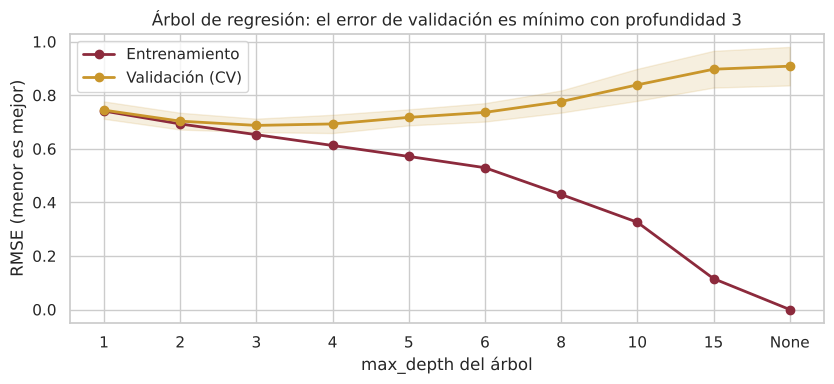

valor,1,2,3,4,5,6,8,10,15,None
RMSE train,0.741,0.693,0.653,0.612,0.571,0.529,0.429,0.326,0.115,-0.000
RMSE validación,0.744,0.703,0.687,0.693,0.717,0.736,0.776,0.839,0.897,0.908
std validación,0.032,0.031,0.025,0.034,0.030,0.034,0.041,0.060,0.069,0.072


Árbol de regresión: 49 combinaciones probadas
  mejor configuración: {'max_depth': 5, 'min_samples_leaf': 40}
  RMSE validación = 0.668 | RMSE entrenamiento = 0.630


In [46]:
#@title **CÓDIGO:** árbol de regresión: curva de profundidad y búsqueda en rejilla
curva_dt_reg = curva_reg(DecisionTreeRegressor(random_state=SEED), "max_depth", [1, 2, 3, 4, 5, 6, 8, 10, 15, None],
                         "Árbol de regresión: el error de validación es mínimo con profundidad 3", "max_depth del árbol")
gs_dt_reg = buscar_reg("Árbol de regresión", DecisionTreeRegressor(random_state=SEED),
                       {"max_depth": [2, 3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 5, 10, 20, 40, 60, 80]})

La curva repite el patrón de la Parte 2: con profundidad 1 o 2 el árbol es demasiado simple (subajuste), el mínimo del error de validación está en profundidad 3, y a partir de ahí el error de entrenamiento sigue bajando hasta 0 mientras el de validación sube (sobreajuste). La búsqueda encuentra que un árbol algo más profundo funciona si cada hoja tiene un mínimo grande de vinos: así las predicciones de cada hoja son promedios de muchos vinos y no copias de uno solo.

### 25.2 Random Forest regresor

Promedia las predicciones de muchos árboles de regresión, cada uno entrenado con una muestra bootstrap y con un subconjunto de variables en cada pregunta. Como en las notas de clase, primero se valida qué pasa al cambiar el número de árboles.

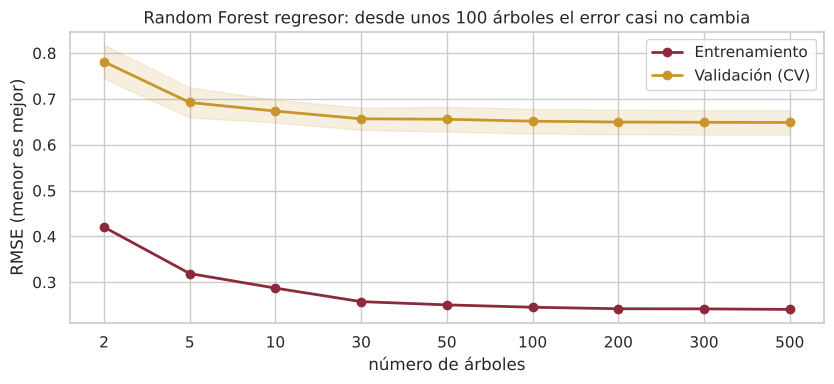

valor,2,5,10,30,50,100,200,300,500
RMSE train,0.420,0.319,0.287,0.258,0.251,0.245,0.242,0.242,0.241
RMSE validación,0.781,0.692,0.673,0.657,0.656,0.651,0.650,0.649,0.649
std validación,0.037,0.033,0.025,0.024,0.027,0.027,0.027,0.027,0.026


Random Forest regresor: 27 combinaciones probadas
  mejor configuración: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5}
  RMSE validación = 0.635 | RMSE entrenamiento = 0.449


In [47]:
#@title **CÓDIGO:** Random Forest regresor: número de árboles y búsqueda en rejilla
curva_rf_reg = curva_reg(RandomForestRegressor(random_state=SEED, n_jobs=-1), "n_estimators", [2, 5, 10, 30, 50, 100, 200, 300, 500],
                         "Random Forest regresor: desde unos 100 árboles el error casi no cambia", "número de árboles")
gs_rf_reg = buscar_reg("Random Forest regresor", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
                       {"max_depth": [8, 12, None], "min_samples_leaf": [1, 3, 5], "max_features": ["sqrt", 0.5, 1.0]})

Con 2 o 5 árboles el promedio es inestable y el error de validación es alto. Desde unos 100 árboles las mejoras son menores que la dispersión entre folds, así que más árboles no ayudan pero tampoco causan sobreajuste. Se fija `n_estimators = 300`, como en la Parte 2, y se ajusta el resto. `max_features = 0.5` significa que en cada pregunta el árbol puede elegir entre la mitad de las variables (5 de 11).

### 25.3 SVR (regresión con máquinas de vectores de soporte)

La SVR adapta la idea de la SVM a la regresión. En vez de una "calle" que separa dos clases, construye un tubo de ancho $\varepsilon$ (épsilon) alrededor de la predicción: los vinos que quedan dentro del tubo no cuentan como error, y solo se penalizan los que quedan afuera. Sus perillas son:

- `C`: cuánto castiga a los vinos que quedan fuera del tubo (igual que en la SVM).
- `gamma`: qué tan lejos llega la influencia de cada vino con el kernel RBF.
- `epsilon`: el ancho del tubo. Un tubo ancho ignora los errores pequeños y da un modelo más simple.
- `kernel` y `degree`: la forma de la función. En clase se propuso probar el kernel polinomial con distintos grados.

Como la SVR usa distancias, siempre va con escalado dentro del `Pipeline`.

In [48]:
#@title **CÓDIGO:** SVR: comparación de kernels (polinomial con grados 1 a 5) y búsqueda en rejilla
filas_kernel = []
for nombre, svr in [("RBF", SVR(kernel="rbf")), ("lineal", SVR(kernel="linear"))] + \
                   [(f"polinomial grado {g}", SVR(kernel="poly", degree=g)) for g in range(1, 6)]:
    filas_kernel.append(resumen_reg(nombre, Pipeline([("escalado", StandardScaler()), ("svr", svr)]), KF5))
tabla_kernels = pd.DataFrame(filas_kernel).set_index("Modelo")
display(tabla_kernels.round(3))

gs_svr_reg = buscar_reg("SVR (RBF)", Pipeline([("escalado", StandardScaler()), ("svr", SVR(kernel="rbf"))]),
                        {"escalado": [StandardScaler(), RobustScaler()],
                         "svr__C": [0.1, 0.3, 1, 3, 10], "svr__gamma": ["scale", 0.01, 0.03, 0.1],
                         "svr__epsilon": [0.1, 0.3, 0.5]})

,RMSE,RMSE (std),MAE,R²,RMSE train
Modelo,,,,,
RBF,0.656,0.025,0.493,0.352,0.554
lineal,0.671,0.017,0.511,0.321,0.660
polinomial grado 1,0.670,0.017,0.511,0.323,0.660
polinomial grado 2,0.873,0.096,0.657,-0.158,0.753
polinomial grado 3,0.930,0.249,0.609,-0.340,0.592
polinomial grado 4,1.513,0.773,0.754,-3.486,0.608
polinomial grado 5,2.642,1.360,0.903,-11.498,0.559


SVR (RBF): 120 combinaciones probadas
  mejor configuración: {'escalado': StandardScaler(), 'svr__C': 1, 'svr__epsilon': 0.3, 'svr__gamma': 0.03}
  RMSE validación = 0.646 | RMSE entrenamiento = 0.607


El kernel polinomial empeora a medida que sube el grado. Con grado 1 equivale a una recta y queda igual que el kernel lineal; con grado 4 o 5 el error de validación se dispara aunque el de entrenamiento siga bajo, porque la curva se dobla demasiado para acomodarse a los vinos de entrenamiento. El kernel RBF es el mejor de todos, y por eso la búsqueda en rejilla se hace con él. La configuración elegida usa un tubo de ancho 0,3: los errores menores a 0,3 puntos no se penalizan.

## 26. Comparación de regresores y selección

Se comparan las líneas base y los tres modelos ajustados con validación cruzada repetida (5 folds × 3 repeticiones, otra semilla).

**Criterio de selección (fijado antes de ver los resultados):** el menor RMSE medio. Si dos modelos quedan a menos de 0,01 de RMSE, se prefiere el de menor MAE.

,RMSE,RMSE (std),MAE,R²,RMSE train
Modelo,,,,,
Random Forest regresor,0.637,0.030,0.495,0.388,0.448
SVR (RBF),0.641,0.033,0.499,0.381,0.607
Línea base: regresión lineal,0.663,0.031,0.514,0.336,0.654
Árbol de regresión,0.674,0.032,0.525,0.316,0.629
Línea base: media,0.817,0.037,0.691,-0.003,0.817


Empate técnico en RMSE (< 0,01): desempata el MAE → Random Forest regresor
Regresor seleccionado: Random Forest regresor (RMSE 0.637 ± 0.030)


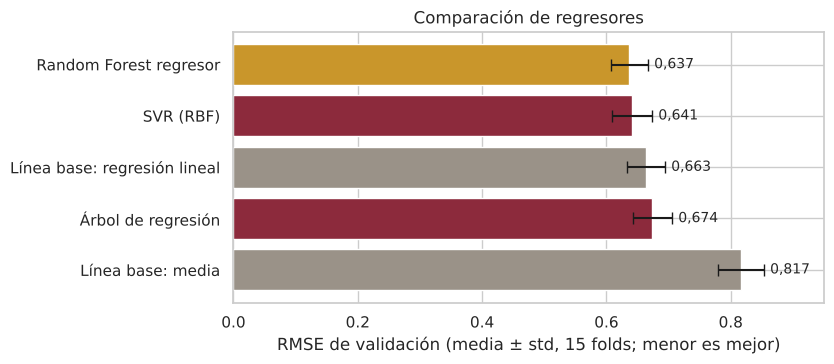

In [49]:
#@title **CÓDIGO:** comparación final con validación cruzada repetida (5 × 3)
candidatos_reg = {"Línea base: media": DummyRegressor(strategy="mean"),
                  "Línea base: regresión lineal": Pipeline([("escalado", StandardScaler()), ("lineal", LinearRegression())])}
candidatos_reg.update({n: g.best_estimator_ for n, g in busquedas_reg.items()})
comparacion_reg = pd.DataFrame([resumen_reg(n, m, KF_REP) for n, m in candidatos_reg.items()]).set_index("Modelo")
comparacion_reg = comparacion_reg.sort_values("RMSE")
display(comparacion_reg.round(3))

ajustados = comparacion_reg.drop(index=[i for i in comparacion_reg.index if i.startswith("Línea base")])
primero, segundo = ajustados.index[0], ajustados.index[1]
if ajustados.loc[segundo, "RMSE"] - ajustados.loc[primero, "RMSE"] < 0.01:
    mejor_reg = ajustados.loc[[primero, segundo], "MAE"].idxmin()
    print(f"Empate técnico en RMSE (< 0,01): desempata el MAE → {mejor_reg}")
else:
    mejor_reg = primero
print(f"Regresor seleccionado: {mejor_reg} (RMSE {comparacion_reg.loc[mejor_reg, 'RMSE']:.3f} ± {comparacion_reg.loc[mejor_reg, 'RMSE (std)']:.3f})")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
orden = comparacion_reg.sort_values("RMSE", ascending=False)
colores = [COLOR_ALTA if n == mejor_reg else ("#9A9288" if n.startswith("Línea base") else COLOR_STD) for n in orden.index]
ax.barh(orden.index, orden["RMSE"], xerr=orden["RMSE (std)"], color=colores, capsize=4)
for i, (v, s) in enumerate(zip(orden["RMSE"], orden["RMSE (std)"])):
    ax.text(v + s + 0.01, i, f"{v:.3f}".replace(".", ","), va="center", fontsize=10)
ax.set_xlabel("RMSE de validación (media ± std, 15 folds; menor es mejor)"); ax.set_xlim(0, 0.95)
ax.set_title("Comparación de regresores"); plt.tight_layout(); plt.show()

Random Forest regresor y SVR quedan prácticamente empatados: RMSE de 0,637 y 0,641, una diferencia de 0,004, menor que el margen de 0,01. Decide el MAE y gana el Random Forest regresor (0,495 frente a 0,499). Los dos superan a la regresión lineal (0,663) y quedan muy por debajo del error de la media (0,817).

El árbol ajustado mejora mucho frente a su versión por defecto (de 0,908 a 0,674), pero no alcanza a la regresión lineal: un solo árbol es demasiado inestable para este problema, igual que en la Parte 2.

Con R² ≈ 0,39, el mejor regresor explica cerca del 39 % de la variación del puntaje. El resto depende de cosas que las 11 mediciones no recogen, como el gusto de cada catador. El Random Forest todavía tiene una brecha entre entrenamiento (0,448) y validación (0,637), aunque menor que la del modelo por defecto (0,245 frente a 0,651).

## 27. Evaluación final del regresor en test

Igual que en la Parte 2, el modelo elegido se reentrena con todo el desarrollo y se evalúa una sola vez en los 272 vinos de test. Los demás se muestran como contexto.

In [50]:
#@title **CÓDIGO:** métricas en test
filas_test_reg, pred_test_reg = [], {}
for nombre, modelo in candidatos_reg.items():
    pred = clone(modelo).fit(X_dev, q_dev).predict(X_test)
    pred_test_reg[nombre] = pred
    etiqueta = f"★ {nombre} (seleccionado)" if nombre == mejor_reg else nombre
    filas_test_reg.append({"Modelo": etiqueta, **metricas_reg(q_test, pred)})
tabla_test_reg = pd.DataFrame(filas_test_reg).set_index("Modelo")
display(tabla_test_reg.round(3))

modelo_reg_final = clone(candidatos_reg[mejor_reg]).fit(X_dev, q_dev)
q_pred = modelo_reg_final.predict(X_test)
cv_test_reg = pd.DataFrame({"Validación cruzada": comparacion_reg.loc[mejor_reg, ["RMSE", "MAE", "R²"]],
                            "Test": pd.Series(metricas_reg(q_test, q_pred))[["RMSE", "MAE", "R²"]]})
print(f"\n{mejor_reg}: validación cruzada frente a test")
display(cv_test_reg.astype(float).round(3))

,MSE,RMSE,MAE,R²,MAPE (%)
Modelo,,,,,
Línea base: media,0.718,0.847,0.709,-0.001,13.223
Línea base: regresión lineal,0.448,0.669,0.509,0.375,9.540
Árbol de regresión,0.499,0.706,0.555,0.305,10.406
★ Random Forest regresor (seleccionado),0.427,0.654,0.502,0.404,9.385
SVR (RBF),0.435,0.660,0.510,0.393,9.551



Random Forest regresor: validación cruzada frente a test


,Validación cruzada,Test
RMSE,0.637,0.654
MAE,0.495,0.502
R²,0.388,0.404


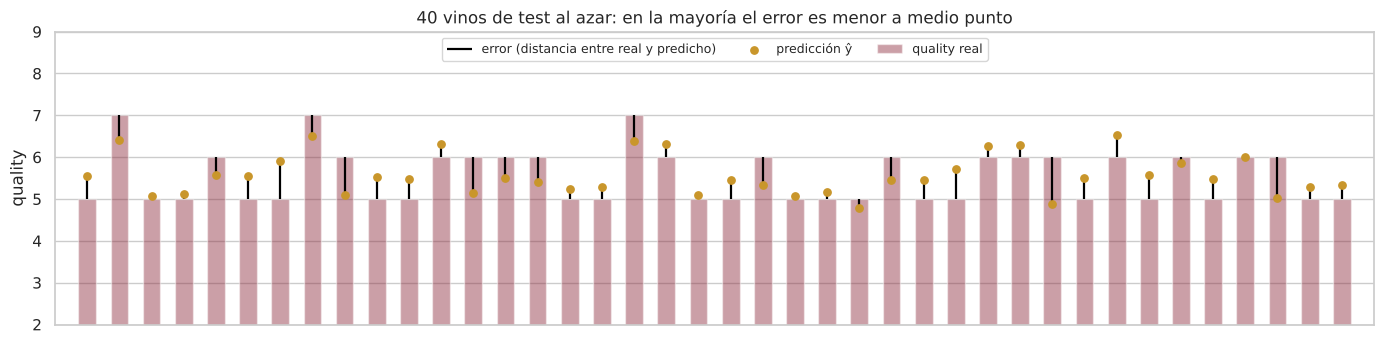

Vinos de test con error menor a 0,5 puntos: 58.5% | menor a 1 punto: 89.0%


In [51]:
#@title **CÓDIGO:** error de 40 vinos de test elegidos al azar (gráfica de las notas de clase)
errores_abs = np.abs(q_test.values - q_pred)
idx = np.random.default_rng(SEED).permutation(len(q_test))[:40]
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.bar(range(len(idx)), q_test.values[idx], width=0.55, color=COLOR_STD, alpha=.45, label="quality real")
ax.vlines(range(len(idx)), q_test.values[idx], q_pred[idx], color="black", lw=1.6, label="error (distancia entre real y predicho)")
ax.scatter(range(len(idx)), q_pred[idx], color=COLOR_ALTA, zorder=3, s=28, label="predicción ŷ")
ax.set_xlim(-1, len(idx)); ax.set_ylim(2, 9); ax.set_xticks([]); ax.set_ylabel("quality")
ax.set_title("40 vinos de test al azar: en la mayoría el error es menor a medio punto")
ax.legend(loc="upper center", fontsize=9, ncol=3, frameon=True); plt.tight_layout(); plt.show()
print(f"Vinos de test con error menor a 0,5 puntos: {(errores_abs < 0.5).mean():.1%} | menor a 1 punto: {(errores_abs < 1).mean():.1%}")

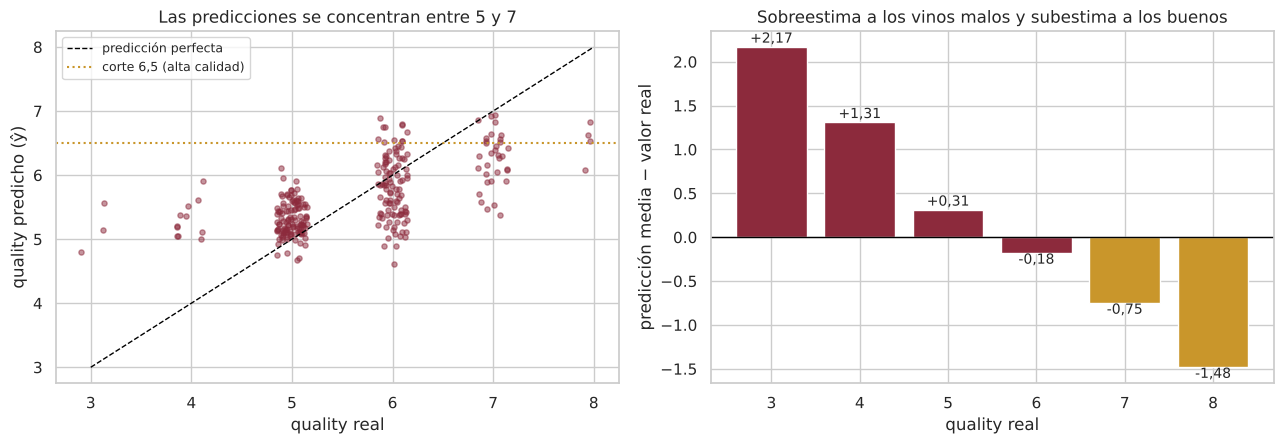

,count,mean,min,max,error medio (pred − real)
real,,,,,
3,3,5.17,4.80,5.56,2.17
4,11,5.31,5.00,5.90,1.31
5,118,5.31,4.67,6.11,0.31
6,103,5.82,4.62,6.90,-0.18
7,33,6.25,5.38,6.94,-0.75
8,4,6.52,6.08,6.83,-1.48


Desviación estándar de las predicciones = 0.52 | de los valores reales = 0.85


In [52]:
#@title **CÓDIGO:** predicción frente a valor real y error por nivel de calidad
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.scatter(q_test + np.random.default_rng(SEED).uniform(-0.15, 0.15, len(q_test)), q_pred, s=14, alpha=.5, color=COLOR_STD)
ax.plot([3, 8], [3, 8], "--", color="black", lw=1, label="predicción perfecta")
ax.axhline(6.5, color=COLOR_ALTA, ls=":", lw=1.5, label="corte 6,5 (alta calidad)")
ax.set_xlabel("quality real"); ax.set_ylabel("quality predicho (ŷ)"); ax.legend(fontsize=9)
ax.set_title("Las predicciones se concentran entre 5 y 7")

por_nivel = pd.DataFrame({"real": q_test.values, "pred": q_pred}).groupby("real")["pred"].agg(["count", "mean", "min", "max"])
por_nivel["error medio (pred − real)"] = por_nivel["mean"] - por_nivel.index
ax = axes[1]
ax.bar(por_nivel.index.astype(str), por_nivel["error medio (pred − real)"],
       color=[COLOR_ALTA if v >= 7 else COLOR_STD for v in por_nivel.index])
ax.axhline(0, color="black", lw=1)
for i, v in enumerate(por_nivel["error medio (pred − real)"]):
    ax.text(i, v + (0.05 if v >= 0 else -0.12), f"{v:+.2f}".replace(".", ","), ha="center", fontsize=10)
ax.set_xlabel("quality real"); ax.set_ylabel("predicción media − valor real")
ax.set_title("Sobreestima a los vinos malos y subestima a los buenos")
plt.tight_layout(); plt.show()
display(por_nivel.round(2))
print(f"Desviación estándar de las predicciones = {q_pred.std():.2f} | de los valores reales = {q_test.std(ddof=0):.2f}")

En test el Random Forest regresor obtiene RMSE = 0,654, MAE = 0,502 y R² = 0,404, muy cerca de lo que anticipaba la validación cruzada (0,637; 0,495 y 0,388). El modelo generaliza: en vinos que nunca vio se equivoca, en promedio, por medio punto. El 58,5 % de los vinos de test tiene un error menor a 0,5 puntos y el 89 % un error menor a 1 punto.

La segunda gráfica muestra su debilidad. Las predicciones tienen una desviación estándar de 0,52, frente a 0,85 de los valores reales: el modelo "encoge" todo hacia la media (5,6). A los vinos de puntaje 3 y 4 les predice en promedio más de 5, y a los de 7 y 8 les predice 6,25 y 6,52. La causa está en cómo aprende: minimizar el error cuadrático premia predecir cerca de los puntajes más comunes (5 y 6 son el 82 % de los datos), y hay muy pocos vinos de los extremos para aprender. Los vinos que más le interesan a la bodega, los de 7 y 8, quedan subestimados.

## 28. Interpretación del regresor y curva de aprendizaje

Se usa la misma importancia por permutación de la Parte 2, ahora midiendo cuánto **sube el RMSE** en test al desordenar cada variable. Así se puede comparar si el regresor y el clasificador se apoyan en las mismas propiedades.

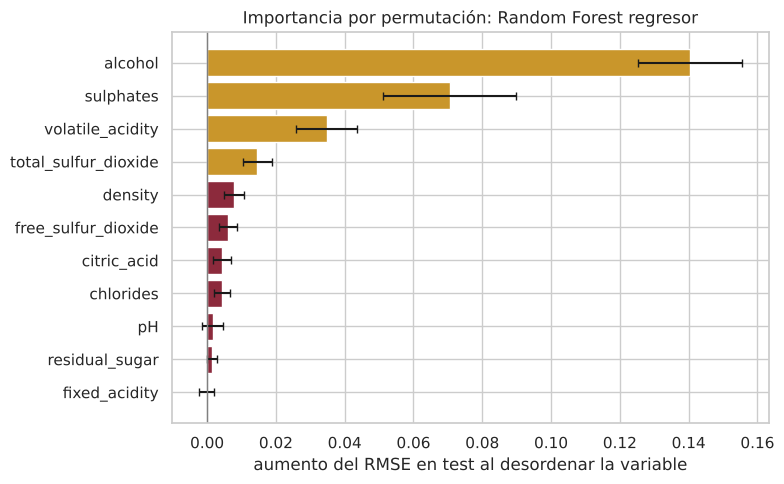

,puesto en regresión,puesto en clasificación (Parte 2),aumento del RMSE
alcohol,1,1,0.140
sulphates,2,2,0.071
volatile_acidity,3,3,0.035
total_sulfur_dioxide,4,8,0.015
density,5,5,0.008
free_sulfur_dioxide,6,11,0.006
citric_acid,7,4,0.004
chlorides,8,6,0.004
pH,9,10,0.002
residual_sugar,10,7,0.001


In [53]:
#@title **CÓDIGO:** importancia por permutación del regresor (aumento del RMSE en test)
perm_reg = permutation_importance(modelo_reg_final, X_test, q_test, scoring="neg_root_mean_squared_error",
                                  n_repeats=30, random_state=SEED, n_jobs=-1)
imp_reg = pd.Series(perm_reg.importances_mean, index=VARIABLES).sort_values()
imp_reg_std = pd.Series(perm_reg.importances_std, index=VARIABLES)[imp_reg.index]

fig, ax = plt.subplots(figsize=(8, 5))
top4_reg = imp_reg.index[-4:]
ax.barh(imp_reg.index, imp_reg.values, xerr=imp_reg_std, capsize=3,
        color=[COLOR_ALTA if v in top4_reg else COLOR_STD for v in imp_reg.index])
ax.set_xlabel("aumento del RMSE en test al desordenar la variable"); ax.axvline(0, color="gray", lw=1)
ax.set_title(f"Importancia por permutación: {mejor_reg}"); plt.tight_layout(); plt.show()

rank_reg = imp_reg.sort_values(ascending=False).rank(ascending=False).astype(int)
if "imp_perm" in globals():
    rank_clf = imp_perm.sort_values(ascending=False).rank(ascending=False).astype(int)
    display(pd.DataFrame({"puesto en regresión": rank_reg, "puesto en clasificación (Parte 2)": rank_clf[rank_reg.index],
                          "aumento del RMSE": imp_reg[rank_reg.index]}).round(3))
else:
    display(pd.DataFrame({"puesto en regresión": rank_reg, "aumento del RMSE": imp_reg[rank_reg.index]}).round(3))

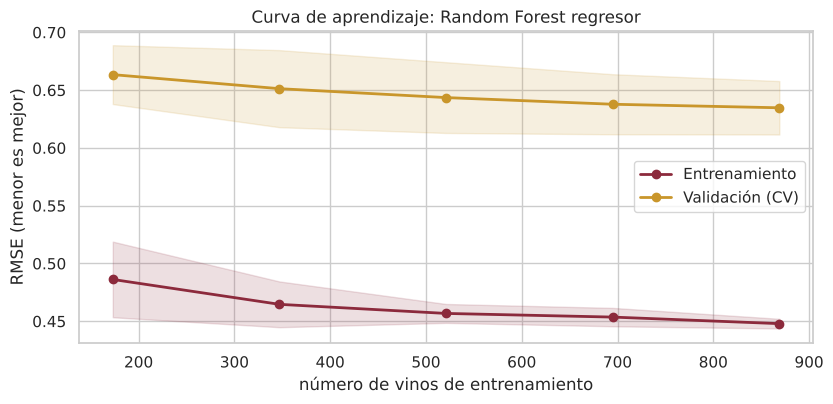

,vinos de entrenamiento,RMSE train,RMSE validación,brecha
0,173,0.486,0.663,0.177
1,347,0.465,0.651,0.187
2,521,0.457,0.644,0.187
3,695,0.454,0.638,0.184
4,869,0.448,0.635,0.187


In [54]:
#@title **CÓDIGO:** curva de aprendizaje del regresor seleccionado
tam_r, tr_r, va_r = learning_curve(clone(modelo_reg_final), X_dev, q_dev, cv=KF5, scoring="neg_root_mean_squared_error",
                                   train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1, shuffle=True, random_state=SEED)
tr_r, va_r = -tr_r, -va_r
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for datos, nombre, color in [(tr_r, "Entrenamiento", COLOR_STD), (va_r, "Validación (CV)", COLOR_ALTA)]:
    ax.plot(tam_r, datos.mean(axis=1), "o-", color=color, lw=2, label=nombre)
    ax.fill_between(tam_r, datos.mean(axis=1) - datos.std(axis=1), datos.mean(axis=1) + datos.std(axis=1), color=color, alpha=.15)
ax.set_xlabel("número de vinos de entrenamiento"); ax.set_ylabel("RMSE (menor es mejor)")
ax.set_title(f"Curva de aprendizaje: {mejor_reg}"); ax.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame({"vinos de entrenamiento": tam_r, "RMSE train": tr_r.mean(axis=1), "RMSE validación": va_r.mean(axis=1),
                      "brecha": va_r.mean(axis=1) - tr_r.mean(axis=1)}).round(3))

El regresor se apoya sobre todo en `alcohol`, `sulphates` y `volatile_acidity`, las mismas tres primeras variables del clasificador. El cambio está en el cuarto puesto: `citric_acid` baja y sube `total_sulfur_dioxide`. Una explicación posible es que el ácido cítrico sirve para separar los vinos de 7 y 8 del resto, que es lo que busca el clasificador, pero ayuda poco a ordenar los vinos de 5 y 6, donde está la mayor parte del error que mide el RMSE.

La curva de aprendizaje muestra que el RMSE de validación baja de 0,663 a 0,635 al pasar de 173 a 869 vinos de entrenamiento, y que la brecha con entrenamiento se mantiene cerca de 0,18. La curva de validación ya está casi plana: más vinos del mismo tipo ayudarían poco.

## 29. Regresión frente a clasificación: ¿cuál responde mejor la pregunta de negocio?

La pregunta del proyecto es si un vino es de alta calidad (`quality ≥ 7`). El regresor se puede usar para responderla de dos maneras:

1. **Con el corte natural:** decir "alta calidad" si $\hat{y} \geq 6{,}5$, es decir, si la predicción se redondea a 7 o más.
2. **Con un corte ajustado:** como el regresor tiende a predecir cerca de la media, quizá conviene un corte más bajo. Para elegirlo sin tocar el test se usan predicciones *out-of-fold* del desarrollo (el mismo procedimiento del umbral en la Parte 2) y se toma el corte que da mayor F1.

También se compara qué tan bien **ordena** los vinos cada enfoque (ROC-AUC y PR-AUC), usando $\hat{y}$ como puntaje del regresor y la probabilidad como puntaje del clasificador.

Corte con mayor F1 en desarrollo (out-of-fold): ŷ ≥ 6.11 (F1 = 0.569); con el corte 6,5 el F1 out-of-fold es 0.423


,F1,Recall,Precision,Vinos marcados como alta,ROC_AUC,PR_AUC
Enfoque,,,,,,
"Clasificador Random Forest (Parte 2, umbral 0.5)",0.571,0.703,0.481,54,0.877,0.513
"Regresor Random Forest regresor, corte ŷ ≥ 6,5",0.452,0.378,0.560,25,0.875,0.520
"Regresor Random Forest regresor, corte ŷ ≥ 6.11 (ajustado en desarrollo)",0.516,0.649,0.429,56,0.875,0.520


Vinos de alta calidad en test: 37
Referencia en desarrollo (out-of-fold): clasificador con umbral 0,5 → F1 = 0.548; con su mejor umbral (0.43) → F1 = 0.555


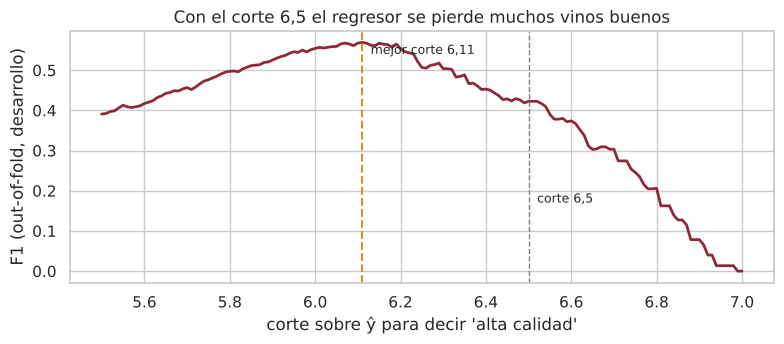

In [55]:
#@title **CÓDIGO:** el regresor usado como clasificador, frente al Random Forest clasificador de la Parte 2
q_oof = cross_val_predict(clone(candidatos_reg[mejor_reg]), X_dev, q_dev, cv=KF5, n_jobs=-1)
cortes = np.round(np.arange(5.5, 7.01, 0.01), 2)
f1_cortes = [f1_score(y_dev, (q_oof >= c).astype(int), zero_division=0) for c in cortes]
corte_opt = cortes[int(np.argmax(f1_cortes))]
print(f"Corte con mayor F1 en desarrollo (out-of-fold): ŷ ≥ {corte_opt:.2f} (F1 = {max(f1_cortes):.3f}); "
      f"con el corte 6,5 el F1 out-of-fold es {f1_score(y_dev, (q_oof >= 6.5).astype(int)):.3f}")

def fila_decision(nombre, puntaje_, corte):
    pred_bin = (puntaje_ >= corte).astype(int)
    return {"Enfoque": nombre, "F1": f1_score(y_test, pred_bin, zero_division=0),
            "Recall": recall_score(y_test, pred_bin, zero_division=0),
            "Precision": precision_score(y_test, pred_bin, zero_division=0),
            "Vinos marcados como alta": int(pred_bin.sum()),
            "ROC_AUC": roc_auc_score(y_test, puntaje_), "PR_AUC": average_precision_score(y_test, puntaje_)}

reg_vs_clf = pd.DataFrame([
    fila_decision(f"Clasificador {modelo_seleccionado} (Parte 2, umbral {UMBRAL})", p_test, UMBRAL),
    fila_decision(f"Regresor {mejor_reg}, corte ŷ ≥ 6,5", q_pred, 6.5),
    fila_decision(f"Regresor {mejor_reg}, corte ŷ ≥ {corte_opt:.2f} (ajustado en desarrollo)", q_pred, corte_opt),
]).set_index("Enfoque")
display(reg_vs_clf.round(3))
print(f"Vinos de alta calidad en test: {int(y_test.sum())}")
if "f1_opt" in globals():
    print(f"Referencia en desarrollo (out-of-fold): clasificador con umbral 0,5 → F1 = {f1_05:.3f}; "
          f"con su mejor umbral ({u_opt:.2f}) → F1 = {f1_opt:.3f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(cortes, f1_cortes, color=COLOR_STD, lw=2)
ax.axvline(6.5, color="gray", ls="--", lw=1); ax.text(6.52, max(f1_cortes) * 0.3, "corte 6,5", fontsize=9)
ax.axvline(corte_opt, color=COLOR_ALTA, ls="--", lw=1.5); ax.text(corte_opt + 0.02, max(f1_cortes) * 0.95, f"mejor corte {corte_opt:.2f}".replace(".", ","), fontsize=9)
ax.set_xlabel("corte sobre ŷ para decir 'alta calidad'"); ax.set_ylabel("F1 (out-of-fold, desarrollo)")
ax.set_title("Con el corte 6,5 el regresor se pierde muchos vinos buenos"); plt.tight_layout(); plt.show()

La tabla deja tres resultados:

1. Con el corte 6,5 el regresor se pierde la mayoría de los vinos buenos. Marca solo 25 vinos como de alta calidad y encuentra 14 de los 37 (recall 0,378). Es la consecuencia directa de que encoja las predicciones: pocos vinos llegan a 6,5.
2. Los dos enfoques ordenan los vinos casi igual de bien. El ROC-AUC es 0,875 para el regresor y 0,877 para el clasificador, y el PR-AUC es 0,520 y 0,513. Usado como puntaje, el regresor sí distingue los vinos buenos; su problema está en dónde poner el corte.
3. Con el corte ajustado (ŷ ≥ 6,11) el regresor mejora, pero no alcanza al clasificador en test: F1 de 0,516 frente a 0,571, con un umbral del clasificador que se dejó en 0,5 sin ajustar.

La diferencia no es concluyente. En desarrollo, con predicciones out-of-fold, los dos quedaron más cerca: 0,569 el regresor con su mejor corte y 0,555 el clasificador con su mejor umbral, ambos optimistas porque el corte se eligió con esos mismos datos. Con 37 vinos buenos en test, unos pocos aciertos cambian el F1 varios puntos.

Aun así, para la pregunta de la bodega la clasificación con pesos de clase sigue siendo la formulación más directa: responde "¿es alta calidad?" sin necesidad de buscar un corte artificial y en test fue la de mayor F1. La regresión aporta otra cosa: un puntaje estimado para cada vino, con un error típico de 0,65 puntos, que sirve para ordenar lotes.

---
# **PARTE 4. CONCLUSIONES DEL PROYECTO**

## 30. Conclusiones generales, limitaciones y trabajo futuro

El proyecto buscaba responder dos preguntas con las 11 mediciones de laboratorio de 1.359 vinos tintos distintos: si se puede identificar un vino de alta calidad (`quality ≥ 7`) y qué propiedades pesan más en la calidad.

### Qué se encontró

1. Para el primer objetivo, clasificar, el mejor modelo es un Random Forest con 300 árboles, `max_depth = 8`, `min_samples_leaf = 5` y pesos de clase. En validación cruzada obtuvo F1 = 0,540 ± 0,051 y en el test final F1 = 0,571: encuentra 26 de los 37 vinos de alta calidad (recall 0,703) y casi la mitad de los vinos que marca lo son (precision 0,481). Supera a la regla `alcohol ≥ 11,6` (F1 = 0,457) y al clasificador trivial (F1 = 0).
2. Para el segundo objetivo, las propiedades que más pesan son `alcohol` (+), `sulphates` (+) y `volatile_acidity` (−): aparecen como las más importantes en el EDA, en el clasificador y en el regresor. `citric_acid` (+) es la cuarta en el EDA y en el clasificador. Son asociaciones: el modelo no prueba que cambiar una propiedad cambie la calidad.
3. Como regresión, el Random Forest regresor predice el puntaje con un error típico de 0,65 puntos (RMSE en test 0,654; MAE 0,502) y explica el 40 % de su variación (R² = 0,404). Supera a la media y a la regresión lineal, pero encoge las predicciones hacia 5,6: subestima los vinos de 7 y 8. Ordena los vinos tan bien como el clasificador (ROC-AUC 0,875 frente a 0,877), aunque para decidir "alta calidad o no" el clasificador fue mejor en test.
4. Los errores del clasificador son de frontera: todos sus falsos positivos son vinos de puntaje 6 y todos sus falsos negativos son de puntaje 7. Nunca marca como premium un vino de 3 a 5.
5. Las decisiones de método que más cambiaron los resultados fueron quitar los 240 duplicados antes de partir, decidir todo con validación cruzada (una sola partición llegó a sobreestimar a GNB en 0,15), usar pesos de clase para el desbalance de 6,4 a 1, controlar la complejidad de los árboles y usar el test una sola vez.

### Uso propuesto

El clasificador puede funcionar como filtro previo a la cata: señala qué lotes podrían ser de alta calidad para que el catador los revise primero. Con el umbral 0,5 detecta cerca del 70 % de los vinos premium. Si a la bodega le cuesta más perder un vino premium que revisar una falsa alarma, puede bajar el umbral. El regresor añade un puntaje estimado para ordenar los lotes. Ninguno de los dos reemplaza al catador.

### Limitaciones

- Hay pocos vinos de alta calidad: 184 en total y 37 en test. Por eso las métricas tienen una incertidumbre de varios puntos.
- Las etiquetas vienen de cata sensorial. Tienen la subjetividad que el proyecto quería reducir, sobre todo entre los puntajes 6 y 7.
- Todos los vinos son tintos de una sola denominación portuguesa (*Vinho Verde*). No se sabe si el modelo funcionaría con otros vinos.
- Las 11 mediciones explican solo el 40 % de la variación del puntaje. El resto depende de factores que el laboratorio no mide.

### Trabajo futuro

- Calibrar las probabilidades del clasificador y fijar el umbral con los costos reales de cada error.
- Probar regresión con más peso para los vinos de los extremos, o modelos ordinales, para corregir el encogimiento hacia la media.
- Usar validación cruzada anidada para estimar con menos optimismo el efecto de elegir hiperparámetros.
- Repetir el análisis con el dataset de vino blanco o con datos de otras bodegas.

## Referencias

1. Cortez, P., Cerdeira, A., Almeida, F., Matos, T. y Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems, 47*(4), 547-553.
2. UCI Machine Learning Repository. Wine Quality: https://archive.ics.uci.edu/dataset/186/wine+quality
3. scikit-learn. Cross-validation: https://scikit-learn.org/stable/modules/cross_validation.html
4. scikit-learn. Ensemble methods (Random Forest, Gradient Boosting): https://scikit-learn.org/stable/modules/ensemble.html
5. scikit-learn. Support Vector Machines (SVC y SVR): https://scikit-learn.org/stable/modules/svm.html
6. scikit-learn. Regression metrics: https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics
7. scikit-learn. Permutation feature importance: https://scikit-learn.org/stable/modules/permutation_importance.html
8. scikit-learn. Common pitfalls and recommended practices: https://scikit-learn.org/stable/common_pitfalls.html
9. Notas de clase del curso: 05 *Data analysis: statistics for class discrimination*, 06 *Intro to ML: classification*, 07 *ML methods* y 08 *Regression*.